# Machine Learning-Based Employee Attrition Prediction and Risk Scoring System
## Project Overview



Employee attrition is a major challenge for organizations because unexpected employee departures can affect productivity, team performance, and business operations.

The objective of this project is to develop a Machine Learning-based system that predicts employee attrition and assigns risk scores to employees based on their work-related and personal attributes.

This project uses employee data from the provided Palo Alto Networks CSV dataset to identify patterns associated with employee attrition and provide insights that may help organizations make better workforce management decisions.

**Project Objectives**

- Understand and analyse employee data.
- Identify factors associated with employee attrition.
- Perform data preprocessing and feature engineering.
- Develop and evaluate Machine Learning classification models.
- Predict employee attrition probabilities.
- Categorize employees into Low, Medium, and High Risk groups.
- Develop an interactive Streamlit dashboard.

**Tools and Technologies**

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Google Colab and Streamlit.

## 1. Importing Required Libraries

In this section, we will import the Python libraries required for data analysis, data manipulation, statistical calculations, and visualization.

These libraries will be used throughout the project to understand the dataset and prepare it for Machine Learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Dataset Upload

The dataset required for this project is provided in CSV format.

In this section, we will upload the employee dataset into the Google Colab environment so that it can be accessed and processed using Python.

In [2]:
from google.colab import files
uploaded = files.upload()

Saving Palo Alto Networks.csv to Palo Alto Networks.csv


## 3. Loading the Dataset

After uploading the CSV file, we will load it into a Pandas DataFrame.

A DataFrame is a tabular data structure that allows us to organize, access, and analyse rows and columns efficiently.

We will use the variable "df" to store our dataset throughout this project.

In [3]:
df = pd.read_csv('/content/Palo Alto Networks.csv')
print("Dataset loaded successfully")

Dataset loaded successfully


## 4. Initial Dataset Inspection

In this section, we will perform an initial inspection of the dataset to understand its structure and contents.

We will examine the first few records, dataset dimensions, and column names to get an overview of the available employee information.

In [4]:
#Display first 5 rows
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2


In [5]:
# Check dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 1470
Number of Columns: 31


In [6]:
# Check column names
print(df.columns.tolist())

['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


## 5. Understanding the Dataset

The employee dataset contains different attributes related to employee demographics, job roles, salary, satisfaction, work experience, and working conditions.

Understanding these attributes is important before performing data analysis and building Machine Learning models.

The target variable for this project is "Attrition", which indicates whether an employee has left the organization or is still working in the company.

In [7]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   int64 
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EnvironmentSatisfaction   1470 non-null   int64 
 9   Gender                    1470 non-null   object
 10  HourlyRate                1470 non-null   int64 
 11  JobInvolvement            1470 non-null   int64 
 12  JobLevel                  1470 non-null   int64 
 13  JobRole                   1470 non-null   object
 14  JobSatisfaction         

In [8]:
# Display numerical columns

numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

print("Numerical Columns:")
print(list(numerical_columns))
print("Number of numerical columns:", len(numerical_columns))

Numerical Columns:
['Age', 'Attrition', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Number of numerical columns: 24


## 6. Data Quality Assessment

In this section, we will examine the quality and structure of the employee dataset before performing Exploratory Data Analysis.

THe main objective is to identify missing values, duplicate records, incorrect data types, and understand the statistical properties of the dataset.

In [9]:
# Check missing values in each column

missing_values = df.isnull().sum()
print(missing_values)

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSinceLastPromotion     0
YearsWithCurrManager        0
dtype: int64


In [10]:
# Total missing values in the dataset

print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [11]:
# Check duplicate records

duplicate_count = df.duplicated().sum()
print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [12]:
# Generste statistical summary

df.describe()

,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,0.161224,802.485714,9.192517,2.912925,2.721769,65.891156,2.729932,2.063946,2.728571,6502.931293,14313.103401,2.693197,15.209524,3.153741,2.712245,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,0.367863,403.509100,8.106864,1.024165,1.093082,20.329428,0.711561,1.106940,1.102846,4707.956783,7117.786044,2.498009,3.659938,0.360824,1.081209,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,0.000000,102.000000,1.000000,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,1009.000000,2094.000000,0.000000,11.000000,3.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,0.000000,465.000000,2.000000,2.000000,2.000000,48.000000,2.000000,1.000000,2.000000,2911.000000,8047.000000,1.000000,12.000000,3.000000,2.000000,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,0.000000,802.000000,7.000000,3.000000,3.000000,66.000000,3.000000,2.000000,3.000000,4919.000000,14235.500000,2.000000,14.000000,3.000000,3.000000,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,0.000000,1157.000000,14.000000,4.000000,4.000000,83.750000,3.000000,3.000000,4.000000,8379.000000,20461.500000,4.000000,18.000000,3.000000,4.000000,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1.000000,1499.000000,29.000000,5.000000,4.000000,100.000000,4.000000,5.000000,4.000000,19999.000000,26999.000000,9.000000,25.000000,4.000000,4.000000,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [13]:
# Statistical summary of categorical columns

df.describe(include='object')

,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,OverTime
count,1470,1470,1470,1470,1470,1470,1470
unique,3,3,6,2,9,3,2
top,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,No
freq,1043,961,606,882,326,673,1054


## 7. Target Variable Analysis

The target variable in this project is Attrition.

It indicates whether an employee has left the organization or is still working in the company.



*   0 represent employees who stayed.
*   1 represent employees who left.

We will analyse the distribution of both classes to understand the class balance in our dataset.


In [14]:
# Count employees in each attrition category

print(df['Attrition'].value_counts())

Attrition
0    1233
1     237
Name: count, dtype: int64


In [15]:
# Calculate attrition percentage

attrition_percentage = df['Attrition'].value_counts(normalize=True)*100
print(attrition_percentage)

Attrition
0    83.877551
1    16.122449
Name: proportion, dtype: float64


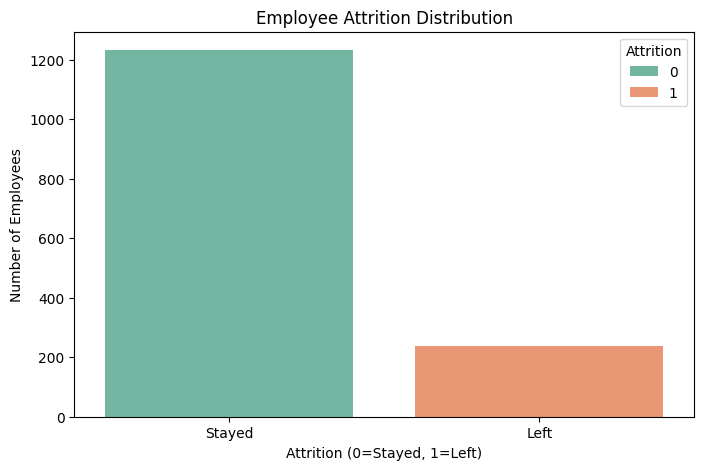

In [16]:
# Visualize attrition distribution

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Attrition', hue='Attrition', palette='Set2', legend=True)

plt.title('Employee Attrition Distribution')
plt.xlabel('Attrition (0=Stayed, 1=Left)')
plt.ylabel('Number of Employees')

plt.xticks([0, 1], ['Stayed', 'Left'])

plt.show()

## Employee Attrition Analysis - Key Findings

The dataset contains 1,470 employee records, out of which 1,233 employees (83.88%) stayed with the organization and 237 employees (16.12%) left.

The target variable shows an imbalanced class distribution, as the number of employees who stayed is significantly higher than those who left.


Employee attrition represents approximately 16.12% of the dataset. Therefore, during model development, we should consider evaluation metrics such as Precision, Recall, and F1-Score along with Accuracy.

# 8. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the patterns, relationships, and distributions present in the employee dataset.

We will use statistical analysis and data visualization techniques to identify factors associated with employee attrition.


## 8.1 Department-wise Attrition Analysis

* Different departments may have differnet employee attrition patterns.

* In this section, we will analyse employee attrition across different departments to identify variations in attrtion rates.

In [17]:
# Calculate department-wise attrition rate

department_rate = df.groupby('Department')['Attrition'].mean()*100
print("Department-wise Attrition Rate:")
print(department_rate.sort_values(ascending=False))

Department-wise Attrition Rate:
Department
Sales                     20.627803
Human Resources           19.047619
Research & Development    13.839750
Name: Attrition, dtype: float64


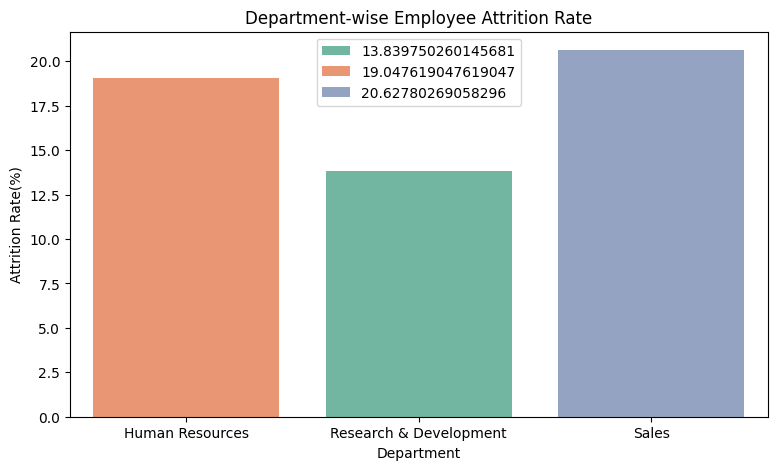

In [18]:
# Visualize department-wise attrition rate

plt.figure(figsize=(9,5))
sns.barplot(
    x=department_rate.index,
    y=department_rate.values,
    hue=department_rate.values,
    palette='Set2',
    legend=True
)

plt.title('Department-wise Employee Attrition Rate')
plt.xlabel('Department')
plt.ylabel('Attrition Rate(%)')
plt.show()

### 8.1.1 Department-wise Analysis – Key Findings

* The Sales department has the highest attrition rate at approximately 20.63%, followed by Human Resources at 19.05%.

* The Research & Development department has the lowest attrition rate at approximately 13.84%.

The Sales department shows comparatively higher employee attrition. This indicates that employee retention strategies may require additional attention in this department.

## 8.2 Job Role-wise Attrition Analysis
* Employees working in different job roles may experience different working conditions and career opportunities.

* In this section, we will analyse attrition rates across different job roles to identify variations in employee retention patterns.


In [19]:
# Calculate job role-wise attrition rate

jobrole_rate = df.groupby('JobRole')['Attrition'].mean()*100
print("Job Role-wise Attrition Rate:")
print(jobrole_rate.sort_values(ascending=False))

Job Role-wise Attrition Rate:
JobRole
Sales Representative         39.759036
Laboratory Technician        23.938224
Human Resources              23.076923
Sales Executive              17.484663
Research Scientist           16.095890
Manufacturing Director        6.896552
Healthcare Representative     6.870229
Manager                       4.901961
Research Director             2.500000
Name: Attrition, dtype: float64


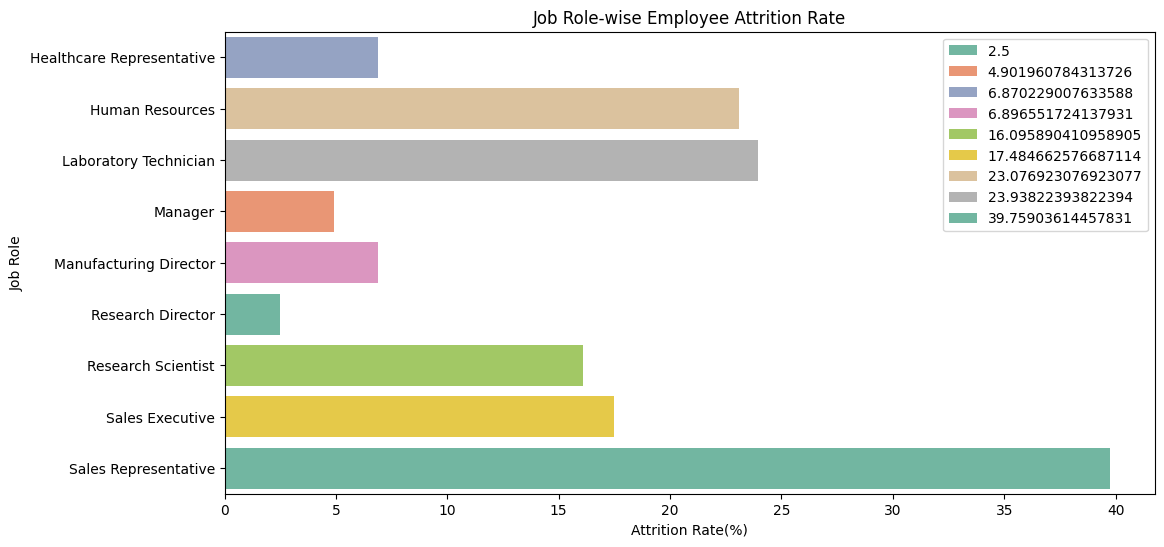

In [20]:
# Visualize job role-wise attrition rate

plt.figure(figsize=(12, 6))
sns.barplot(
    x=jobrole_rate.values,
    y=jobrole_rate.index,
    hue=jobrole_rate.values,
    palette='Set2',
    legend=True
)

plt.title('Job Role-wise Employee Attrition Rate')
plt.xlabel('Attrition Rate(%)')
plt.ylabel('Job Role')

plt.show()

### 8.2.1 Job Role-wise Analysis – Key Findings

* The Sales Representative role has the highest attrition rate at approximately 39.76%, followed by Laboratory Technician at 23.94% and Human Resources at 23.08%.

* The Research Director role has the lowest attrition rate at approximately 2.50%.


The analysis highlights significant differences in attrition rates across job roles. The Sales Representative role may require closer examination to understand the factors associated with higher employee turnover.

## 8.3 Overtime and Employee Attrition Analysis


* Overtime is an important work-related factor that may be associated with employee workload and work-life balance.

* In this section, we will compare attrition rates between employees who work overtime and those who do not.

In [21]:
# Calculate overtime-wise attrition rate

overtime_rate = df.groupby('OverTime')['Attrition'].mean()*100
print("Overtime-wise Attrition Rate:")
print(overtime_rate.sort_values(ascending=False))

Overtime-wise Attrition Rate:
OverTime
Yes    30.528846
No     10.436433
Name: Attrition, dtype: float64


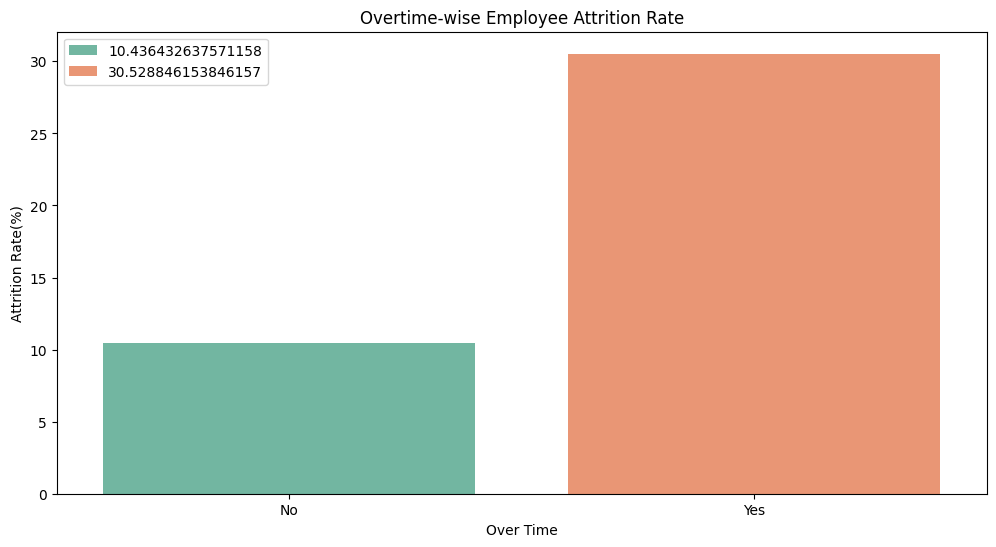

In [22]:
# Visualize job role-wise attrition rate

plt.figure(figsize=(12, 6))
sns.barplot(
    x=overtime_rate.index,
    y=overtime_rate.values,
    hue=overtime_rate.values,
    palette='Set2',
    legend=True
)

plt.title('Overtime-wise Employee Attrition Rate')
plt.xlabel('Over Time')
plt.ylabel('Attrition Rate(%)')

plt.show()

### 8.3.1 Overtime Analysis – Key Findings

* Employees who work overtime have an attrition rate of approximately 30.53%, whereas employees who do not work overtime have an attrition rate of approximately 10.44%.

*  This shows a considerable difference in attrition rates between the two groups.

* Employees working overtime show a higher attrition rate. Organizations may benefit from reviewing workload distribution and work-life balance practices to improve employee retention.

However, this relationship does not necessarily establish overtime as the direct cause of employee attrition.

## 8.4 Job Satisfaction and Employee Attrition
* Job satisfaction represents how satisfied employes are with their jobs.

* In this section, we will analyse attrition rates across different job satisfaction levels to understand whether satisfaction levels are associated with employee retention.

In [23]:
# Calculate job satisfaction-wise attrition rate

satisfaction_rate = df.groupby('JobSatisfaction')['Attrition'].mean()*100
print("Job Satisfaction-wise Attrition Rate:")
print(satisfaction_rate.sort_values(ascending=False))

Job Satisfaction-wise Attrition Rate:
JobSatisfaction
1    22.837370
3    16.515837
2    16.428571
4    11.328976
Name: Attrition, dtype: float64


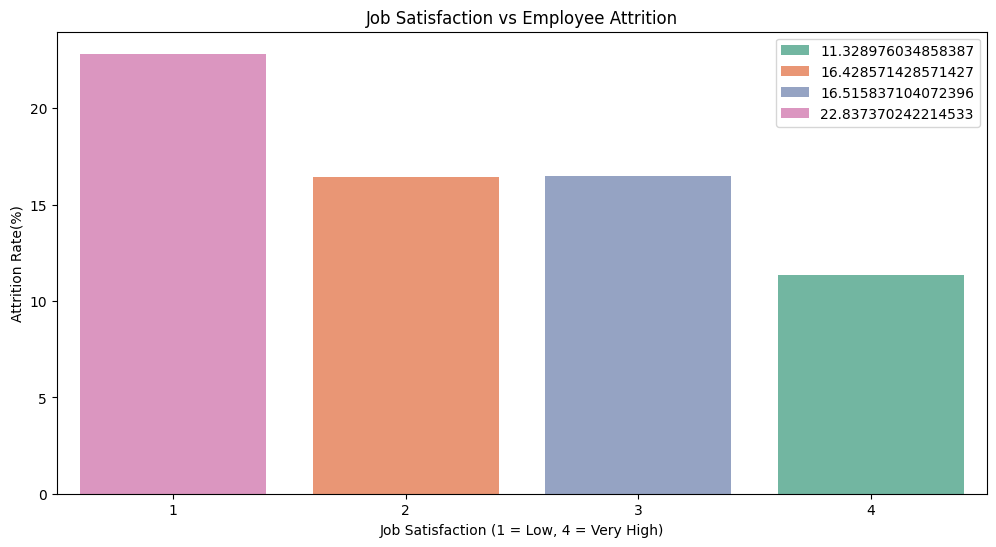

In [24]:
# Visualize job role-wise attrition rate

plt.figure(figsize=(12, 6))
sns.barplot(
    x=satisfaction_rate.index,
    y=satisfaction_rate.values,
    hue=satisfaction_rate.values,
    palette='Set2',
    legend=True
)

plt.title('Job Satisfaction vs Employee Attrition')
plt.xlabel('Job Satisfaction (1 = Low, 4 = Very High)')
plt.ylabel('Attrition Rate(%)')

plt.show()

### 8.4.1 Job Satisfaction – Key Findings

* Employees with low job satisfaction (Level 1) have the highest attrition rate at approximately 22.84%.

* Employees with very high job satisfaction (Level 4) have the lowest attrition rate at approximately 11.33%.

* The results indicate that higher job satisfaction is generally associated with lower employee attrition.

Organizations should pay attention to employee satisfaction and workplace experience as part of their employee retention strategies.

## 8.5 Age Distribution and Employee Attrition
* Age is an important demographic attribute in the employee dataset.

* In this section, we will examine the age distribution of employees and compare age patters between employees who stayed and those who left the organization.

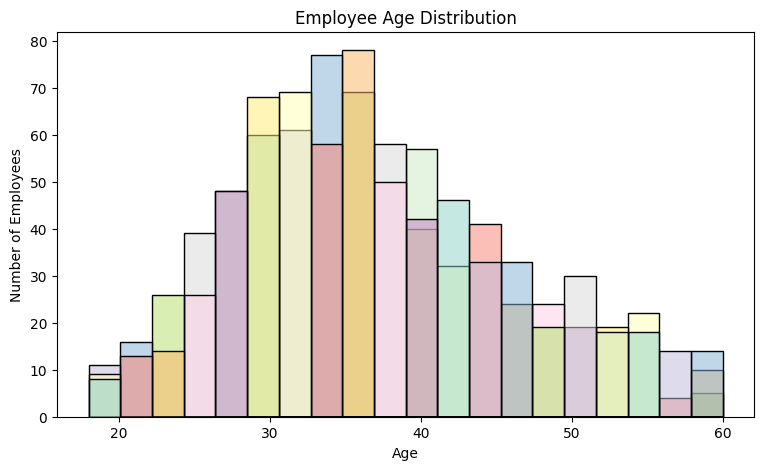

In [25]:
# Visualize employee age distribution

plt.figure(figsize=(9,5))

sns.histplot(data=df, x='Age', bins = 20, kde=True, hue=df['Age'], palette='Set3', legend=False)

plt.title('Employee Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Employees')

plt.show()

### 8.5.1 Age Distribution – Key Findings

* The employee age distribution ranges approximately from 18 to 60 years.

* Most employees are concentrated in the age group of approximately 30 to 40 years, while relatively fewer employees are present in the higher age groups.

The dataset represents employees from different age groups, allowing us to further investigate whether age distributions differ between employees who stayed and those who left the organization.

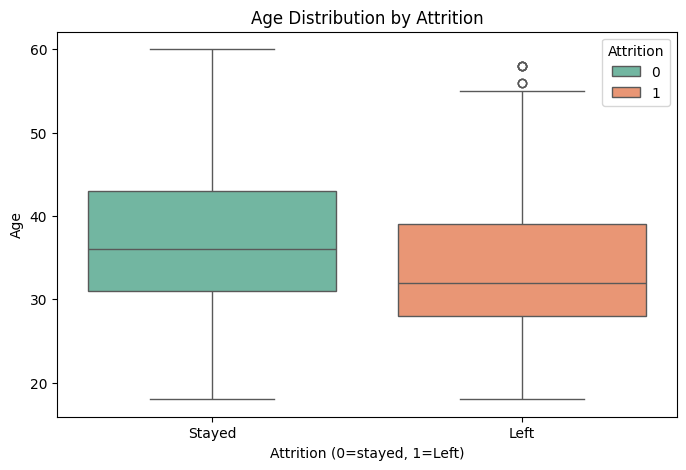

In [26]:
# Compare age distribution by attrition

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Attrition',
    y='Age',
    hue='Attrition',
    palette='Set2',
    legend=True
)

plt.title('Age Distribution by Attrition')
plt.xlabel('Attrition (0=stayed, 1=Left)')
plt.ylabel('Age')
plt.xticks([0, 1], ['Stayed', 'Left'])

plt.show()

### 8.5.2 Age-wise Comparison – Key Findings


* The boxplot shows a difference in age distribution between employees who stayed and those who left the organization.

* The median age of employees who stayed is approximately 36 years, whereas the median age of employees who left is approximately 32 years.

* The middle 50% of employees who stayed fall approximately between 31 and 43 years, while employees who left fall between 28 and 39 years.

* A few higher-age observations are also identified as potential outliers in the attrition group.

The analysis indicates that employees who left the organization are comparatively younger in terms of their median age. This suggests a possible association between age and employee attrition.

However, age alone cannot explain employee attrition. Other factors such as job satisfaction, overtime, compensation, and career growth should also be considered.

Note: Outliers represent observations that fall outside the typical range of the data. They are not necessarily incorrect records and should be investigated before deciding whether any treatment is required.

In [27]:
# Compare age statistics by attrition

age_summary = df.groupby('Attrition')['Age'].describe()

print(age_summary)

            count       mean      std   min   25%   50%   75%   max
Attrition                                                          
0          1233.0  37.561233  8.88836  18.0  31.0  36.0  43.0  60.0
1           237.0  33.607595  9.68935  18.0  28.0  32.0  39.0  58.0


In [28]:
# Identify potential age outliers using IQR method

left_employees = df[df['Attrition'] == 1]

Q1 = left_employees['Age'].quantile(0.25)
Q3 = left_employees['Age'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = left_employees[
    (left_employees['Age'] < lower_limit) |
    (left_employees['Age'] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Potential Outliers:", len(outliers))

print("\nOutlier Ages:")
print(outliers['Age'].value_counts().sort_index())

Lower Limit: 11.5
Upper Limit: 55.5
Number of Potential Outliers: 8

Outlier Ages:
Age
56    3
58    5
Name: count, dtype: int64


### 8.5.3 Additional Statistical Findings

* The statistical analysis shows that employees who stayed have an average age of 37.56 years, compared to 33.61 years for employees who left.

* Using the IQR method, 8 potential age outliers were identified among employees who left. These observations include 3 employees aged 56 and 5 employees aged 58.

### 8.5.4 Age Analysis – Conclusion

The identified outliers represent approximately 3.38% of employees who left. Since these age values may represent valid employee records, they will be retained unless further investigation identifies data quality issues.

## 8.6 Monthly Income Analysis
* Monthly income is an important compensation-related feature in the employee dataset.

* In this section, we will compare monthly income distributions between employees who stayed and employees who left the organization.

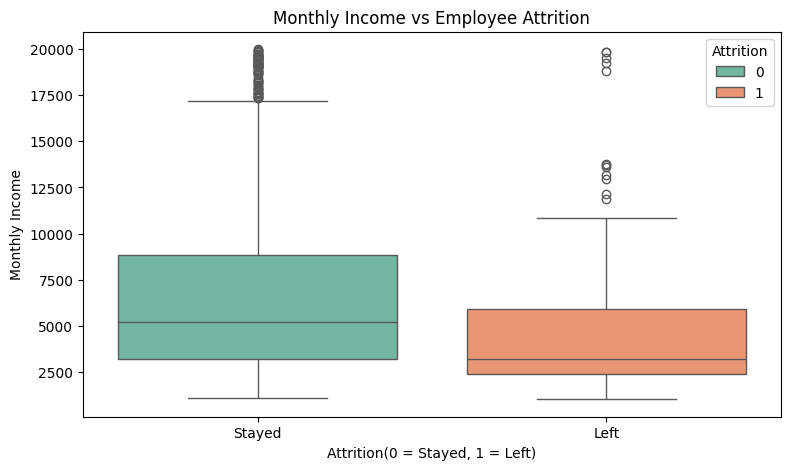

In [29]:
# Compare monthly income by attrition

plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x='Attrition',
    y='MonthlyIncome',
    hue='Attrition',
    palette='Set2',
    legend=True
)

plt.title('Monthly Income vs Employee Attrition')
plt.xlabel('Attrition(0 = Stayed, 1 = Left)')
plt.ylabel('Monthly Income')

plt.xticks([0,1], ['Stayed', 'Left'])

plt.show()

### 8.6.1 Monthly Income – Key Findings

* The boxplot indicates that employees who stayed have a median monthly income of approximately 5,200, whereas employees who left have a median monthly income of approximately 3,000.

* This suggests that employees who left the organization generally have lower median monthly income compared to employees who stayed.

* The distribution also contains some high-income outliers in both categories.

Compensation may be associated with employee retention. Organizations should consider reviewing compensation structures and career growth opportunities while analysing employee attrition.

## 8.7 Work Experience and Employee Attrition

* Work experience and company tenure provide information about an employee's professional background and duration of employment.

* In this section, we will compare total working experience and years spent at the company between employees who stayed and those who left.

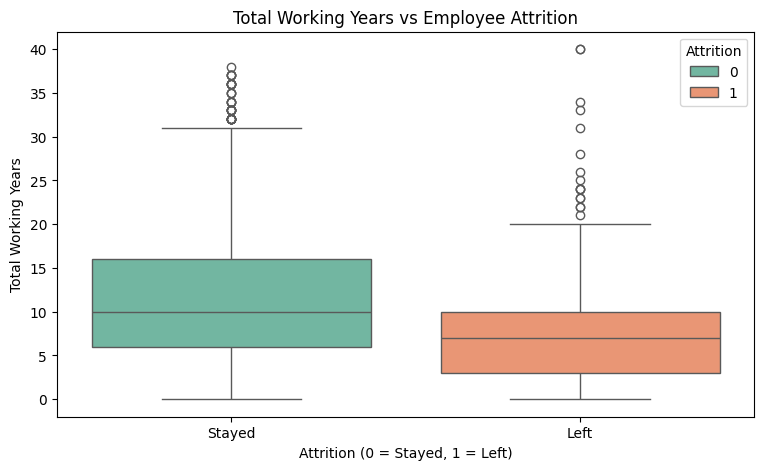

In [30]:
# Compare total working years by attrition

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Attrition',
    y='TotalWorkingYears',
    hue='Attrition',
    palette='Set2',
    legend=True
)

plt.title('Total Working Years vs Employee Attrition')
plt.xlabel('Attrition (0 = Stayed, 1 = Left)')
plt.ylabel('Total Working Years')

plt.xticks([0, 1], ['Stayed', 'Left'])

plt.show()

### 8.7.1 Total Work Experience – Key Findings

* The boxplot shows that employees who stayed have a median total working experience of approximately 10 years, whereas employees who left have a median experience of approximately 7 years.

* This indicates that employees who left generally have comparatively lower total professional experience.

Work experience may be associated with employee retention patterns. HR teams can further investigate career development opportunities and employee expectations across different experience levels.

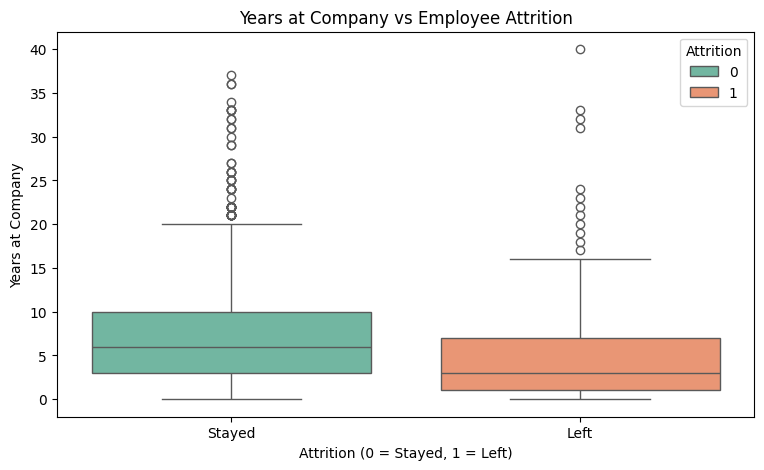

In [31]:
# Compare years at company by attrition

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Attrition',
    y='YearsAtCompany',
    hue='Attrition',
    palette='Set2',
    legend=True
)

plt.title('Years at Company vs Employee Attrition')
plt.xlabel('Attrition (0 = Stayed, 1 = Left)')
plt.ylabel('Years at Company')

plt.xticks([0, 1], ['Stayed', 'Left'])

plt.show()

### 8.7.2 Company Tenure – Key Findings

* The boxplot indicates that employees who stayed have a median company tenure of approximately 6 years, whereas employees who left have a median tenure of approximately 2 years.

* This suggests that employees who left generally spent fewer years with the organization compared to employees who stayed.

Employee retention may require additional attention during the initial years of employment. Organizations can consider improving onboarding, employee engagement, and career development opportunities.

## 8.8 Correlation Analysis

* Correlation analysis helps us understand the strength and direction of relationships between numerical variables.

* In this section, we will calculate correlation coefficients and visualize them using a correlation heatmap.

* This analysis will help us identify numerical features that show relationships with the target variable "Attrition".

In [32]:
# Calculate correlation matrix

correlation_matrix = df.corr(numeric_only=True)

correlation_matrix

,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
Age,1.000000,-0.159205,0.010661,-0.001686,0.208034,0.010146,0.024287,0.029820,0.509604,-0.004892,0.497855,0.028051,0.299635,0.003634,0.001904,0.053535,0.037510,0.680381,-0.019621,-0.021490,0.311309,0.212901,0.216513,0.202089
Attrition,-0.159205,1.000000,-0.056652,0.077924,-0.031373,-0.103369,-0.006846,-0.130016,-0.169105,-0.103481,-0.159840,0.015170,0.043494,-0.013478,0.002889,-0.045872,-0.137145,-0.171063,-0.059478,-0.063939,-0.134392,-0.160545,-0.033019,-0.156199
DailyRate,0.010661,-0.056652,1.000000,-0.004985,-0.016806,0.018355,0.023381,0.046135,0.002966,0.030571,0.007707,-0.032182,0.038153,0.022704,0.000473,0.007846,0.042143,0.014515,0.002453,-0.037848,-0.034055,0.009932,-0.033229,-0.026363
DistanceFromHome,-0.001686,0.077924,-0.004985,1.000000,0.021042,-0.016075,0.031131,0.008783,0.005303,-0.003669,-0.017014,0.027473,-0.029251,0.040235,0.027110,0.006557,0.044872,0.004628,-0.036942,-0.026556,0.009508,0.018845,0.010029,0.014406
Education,0.208034,-0.031373,-0.016806,0.021042,1.000000,-0.027128,0.016775,0.042438,0.101589,-0.011296,0.094961,-0.026084,0.126317,-0.011111,-0.024539,-0.009118,0.018422,0.148280,-0.025100,0.009819,0.069114,0.060236,0.054254,0.069065
EnvironmentSatisfaction,0.010146,-0.103369,0.018355,-0.016075,-0.027128,1.000000,-0.049857,-0.008278,0.001212,-0.006784,-0.006259,0.037600,0.012594,-0.031701,-0.029548,0.007665,0.003432,-0.002693,-0.019359,0.027627,0.001458,0.018007,0.016194,-0.004999
HourlyRate,0.024287,-0.006846,0.023381,0.031131,0.016775,-0.049857,1.000000,0.042861,-0.027853,-0.071335,-0.015794,-0.015297,0.022157,-0.009062,-0.002172,0.001330,0.050263,-0.002334,-0.008548,-0.004607,-0.019582,-0.024106,-0.026716,-0.020123
JobInvolvement,0.029820,-0.130016,0.046135,0.008783,0.042438,-0.008278,0.042861,1.000000,-0.012630,-0.021476,-0.015271,-0.016322,0.015012,-0.017205,-0.029071,0.034297,0.021523,-0.005533,-0.015338,-0.014617,-0.021355,0.008717,-0.024184,0.025976
JobLevel,0.509604,-0.169105,0.002966,0.005303,0.101589,0.001212,-0.027853,-0.012630,1.000000,-0.001944,0.950300,0.039563,0.142501,-0.034730,-0.021222,0.021642,0.013984,0.782208,-0.018191,0.037818,0.534739,0.389447,0.353885,0.375281
JobSatisfaction,-0.004892,-0.103481,0.030571,-0.003669,-0.011296,-0.006784,-0.071335,-0.021476,-0.001944,1.000000,-0.007157,0.000644,-0.055699,0.020002,0.002297,-0.012454,0.010690,-0.020185,-0.005779,-0.019459,-0.003803,-0.002305,-0.018214,-0.027656


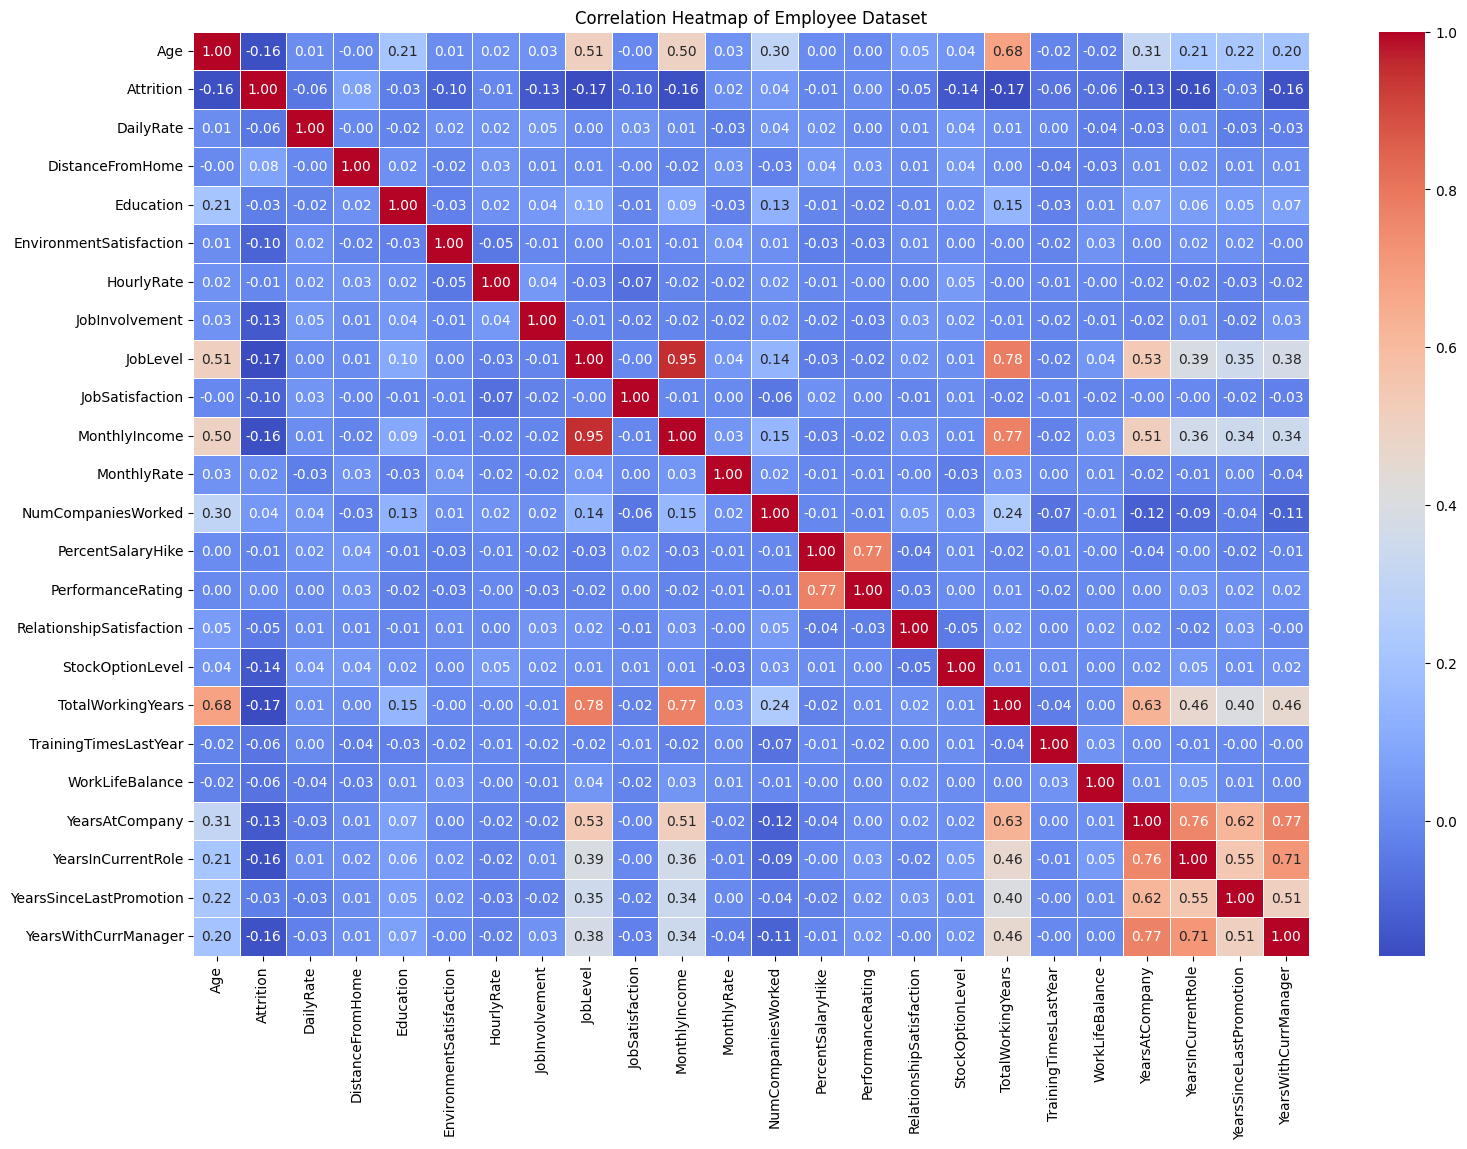

In [33]:
# Visualize correlation matrix

plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Employee Dataset')

plt.show()

In [34]:
# Find correlation of all numerical features with Attrition

attrition_correlation = correlation_matrix['Attrition'].sort_values(
    ascending=False
)

print("Correlation with Attrition:")
print(attrition_correlation)

Correlation with Attrition:
Attrition                   1.000000
DistanceFromHome            0.077924
NumCompaniesWorked          0.043494
MonthlyRate                 0.015170
PerformanceRating           0.002889
HourlyRate                 -0.006846
PercentSalaryHike          -0.013478
Education                  -0.031373
YearsSinceLastPromotion    -0.033019
RelationshipSatisfaction   -0.045872
DailyRate                  -0.056652
TrainingTimesLastYear      -0.059478
WorkLifeBalance            -0.063939
EnvironmentSatisfaction    -0.103369
JobSatisfaction            -0.103481
JobInvolvement             -0.130016
YearsAtCompany             -0.134392
StockOptionLevel           -0.137145
YearsWithCurrManager       -0.156199
Age                        -0.159205
MonthlyIncome              -0.159840
YearsInCurrentRole         -0.160545
JobLevel                   -0.169105
TotalWorkingYears          -0.171063
Name: Attrition, dtype: float64


### 8.8.1 Correlation Analysis – Key Findings

* The correlation analysis shows that most numerical features have relatively weak linear relationships with the target variable "Attrition".

* The strongest negative correlations with Attrition are observed for:

      * TotalWorkingYears: -0.1711
      * JobLevel: -0.1691
      * YearsInCurrentRole: -0.1605
      * MonthlyIncome: -0.1598
      * Age: -0.1592

* DistanceFromHome shows a weak positive correlation of approximately 0.0779 with Attrition.

* The heatmap also reveals a strong positive correlation of approximately 0.95 between JobLevel and MonthlyIncome.

The results suggest that employee experience, job level, income, and age have some negative linear associations with attrition. However, these relationships are relatively weak.

Therefore, employee attrition should be investigated using multiple features rather than relying on a single numerical variable.

### 8.8.2 Correlation Analysis – Conclusion

Correlation analysis provides an initial understanding of numerical relationships. Further analysis and Machine Learning techniques will be required to identify more complex patterns associated with employee attrition.

**Note:** Correlation indicates association, not causation.

## 8.9 Additional Analysis: Sales Representative Attrition Factors

* The previous analysis identified Sales Representatives as the job role with the highest attrition rate of approximately 39.76%.

* In this section, we will investigate different employee-related factors within the Sales Representative role.

* The analysis will focus on overtime, job satisfaction, monthly income, work-life balance, and company tenure to identify characteristics associated with employee attrition.

* The objective is to gain deeper insights into the attrition patterns within this specific job role.

In [35]:
# Filter Sales Representative employees

sales_rep = df[df['JobRole'] == 'Sales Representative'].copy()

print("Total Sales Representatives:", len(sales_rep))

print("\nAttrition Distribution:")
print(sales_rep['Attrition'].value_counts())

Total Sales Representatives: 83

Attrition Distribution:
Attrition
0    50
1    33
Name: count, dtype: int64


### 8.9.1 Overtime Analysis

* In this section, we will examine whether overtime status is associated with employee attrition among Sales Representatives.

* We will compare attrition percentages between employees who work overtime and those who do not.

In [36]:
# Analyze overtime and attrition

sales_overtime = pd.crosstab(
    sales_rep['OverTime'],
    sales_rep['Attrition'],
    normalize='index'
) * 100

print(sales_overtime)

Attrition          0          1
OverTime                       
No         71.186441  28.813559
Yes        33.333333  66.666667


### 8.9.2 Job Satisfaction Analysis

* This section examines the relationship between job satisfaction levels and employee attrition among Sales Representatives.

In [37]:
# Analyze job satisfaction and attrition

sales_satisfaction = sales_rep.groupby(
    'JobSatisfaction'
)['Attrition'].mean() * 100

print("Job Satisfaction-wise Attrition Rate:")
print(sales_satisfaction)

Job Satisfaction-wise Attrition Rate:
JobSatisfaction
1    58.333333
2    47.619048
3    33.333333
4    30.434783
Name: Attrition, dtype: float64


### 8.9.3 Monthly Income Analysis

* In this section, we will compare the median monthly income of Sales Representatives who stayed and those who left the organization.

In [38]:
# Compare monthly income by attrition

sales_income = sales_rep.groupby(
    'Attrition'
)['MonthlyIncome'].median()

print("Median Monthly Income:")
print(sales_income)

Median Monthly Income:
Attrition
0    2643.0
1    2325.0
Name: MonthlyIncome, dtype: float64


### 8.9.4 Work-Life Balance Analysis

* Work-life balance is an important employee-related factor.

* In this section, we will compare attrition rates across different work-life balance levels among Sales Representatives.

In [39]:
# Analyze work-life balance and attrition

sales_worklife = sales_rep.groupby(
    'WorkLifeBalance'
)['Attrition'].mean() * 100

print("Work-Life Balance-wise Attrition Rate:")
print(sales_worklife)

Work-Life Balance-wise Attrition Rate:
WorkLifeBalance
1     0.000000
2    37.500000
3    33.333333
4    88.888889
Name: Attrition, dtype: float64


### 8.9.5 Company Tenure Analysis

* In this section, we will compare the company tenure of Sales Representatives who stayed and those who left.

* This analysis will help us understand differences in employee retention patterns based on years spent in the organization.

In [40]:
# Compare company tenure by attrition

sales_tenure = sales_rep.groupby(
    'Attrition'
)['YearsAtCompany'].median()

print("Median Years at Company:")
print(sales_tenure)

Median Years at Company:
Attrition
0    2.0
1    1.0
Name: YearsAtCompany, dtype: float64


### 8.9.6 Preliminary Findings

The additional analysis of Sales Representatives reveals several patterns associated with employee attrition:

1. **Overtime:** Employees working overtime show a higher attrition rate (66.67%) compared to those not working overtime (28.81%).

2. **Job Satisfaction:** Lower job satisfaction levels are generally associated with higher attrition rates.

3. **Monthly Income:** Employees who left had a lower median monthly income (2,325) compared to employees who stayed (2,643).

4. **Work-Life Balance:** The highest attrition rate (88.89%) was observed at work-life balance level 4. This unusual result requires further investigation of the number of employees in each category.

5. **Company Tenure:** Employees who left had a median company tenure of 1 year, compared to 2 years for employees who stayed.


Overtime, job satisfaction, compensation, and early company tenure emerge as important areas for further investigation within the Sales Representative role.

These findings indicate associations rather than confirmed reasons for employee resignations. Category-wise sample sizes should also be considered before drawing final conclusions.

In [41]:
# Verify employee counts for Sales Representatives

print("OVERTIME - EMPLOYEE COUNTS")
print(pd.crosstab(
    sales_rep['OverTime'],
    sales_rep['Attrition']
))

print("\nJOB SATISFACTION - EMPLOYEE COUNTS")
print(pd.crosstab(
    sales_rep['JobSatisfaction'],
    sales_rep['Attrition']
))

print("\nWORK-LIFE BALANCE - EMPLOYEE COUNTS")
print(pd.crosstab(
    sales_rep['WorkLifeBalance'],
    sales_rep['Attrition']
))

OVERTIME - EMPLOYEE COUNTS
Attrition   0   1
OverTime         
No         42  17
Yes         8  16

JOB SATISFACTION - EMPLOYEE COUNTS
Attrition         0   1
JobSatisfaction        
1                 5   7
2                11  10
3                18   9
4                16   7

WORK-LIFE BALANCE - EMPLOYEE COUNTS
Attrition         0   1
WorkLifeBalance        
1                 1   0
2                10   6
3                38  19
4                 1   8


### 8.9.7 Overtime Visualization

* This visualization compares employee attrition rates among Sales Representatives based on their overtime status.

* It highlights the difference in employee retention between those who work overtime and those who do not, along with the corresponding employee counts.

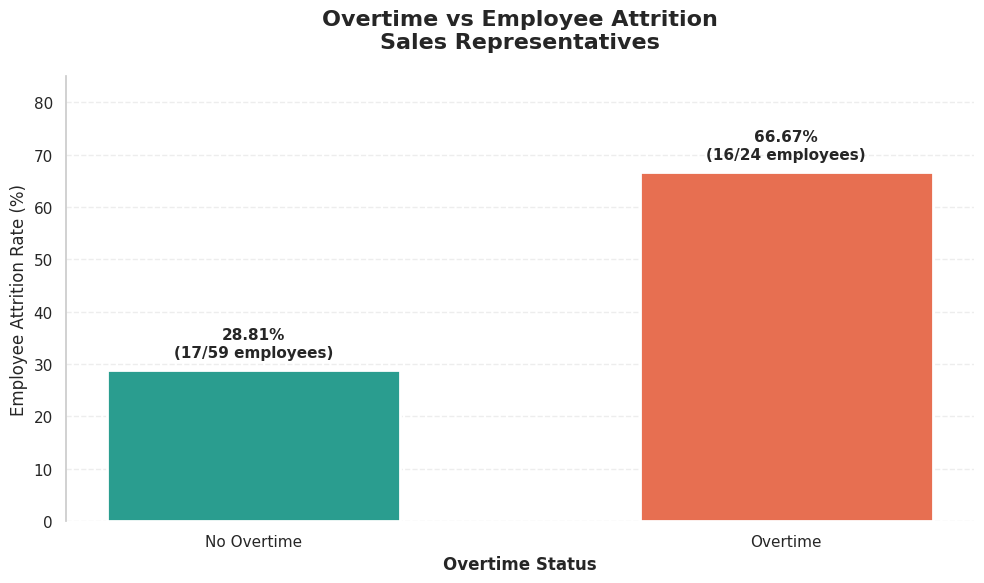

In [42]:
# Overtime vs Employee Attrition - Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate attrition percentages
overtime_plot = pd.crosstab(
    sales_rep['OverTime'],
    sales_rep['Attrition'],
    normalize='index'
) * 100

# Calculate employee counts
overtime_counts = sales_rep['OverTime'].value_counts()

# Prepare attrition rates
attrition_rates = overtime_plot[1].reindex(['No', 'Yes'])

# Set professional visual style
sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#2A9D8F', '#E76F51']

bars = ax.bar(
    ['No Overtime', 'Overtime'],
    attrition_rates.values,
    color=colors,
    width=0.55,
    edgecolor='white',
    linewidth=2
)

# Add percentage and employee count labels
for bar, rate, category in zip(
    bars,
    attrition_rates.values,
    ['No', 'Yes']
):
    total = overtime_counts[category]
    left = sales_rep[
        (sales_rep['OverTime'] == category) &
        (sales_rep['Attrition'] == 1)
    ].shape[0]

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f'{rate:.2f}%\n({left}/{total} employees)',
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

# Titles and labels
ax.set_title(
    'Overtime vs Employee Attrition\nSales Representatives',
    fontsize=16,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Overtime Status', fontsize=12, fontweight='bold')
ax.set_ylabel('Employee Attrition Rate (%)', fontsize=12)

ax.set_ylim(0, 85)

# Grid and formatting
ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.grid(axis='x', visible=False)

sns.despine(left=False, bottom=True)

plt.tight_layout()
plt.show()

#### 8.9.7.1 Overtime Visualization – Key Findings

The analysis reveals a significant difference in attrition rates based on overtime status.

- Employees working overtime have an attrition rate of 66.67% (16 out of 24 employees).
- Employees not working overtime have an attrition rate of 28.81% (17 out of 59 employees).
- The difference indicates that overtime status is strongly associated with employee attrition in the Sales Representative group.

The organization should review overtime policies, workload distribution, and employee work-life balance to identify potential retention concerns.

### 8.9.8 Job Satisfaction Visualization

- This analysis examines how employee job satisfaction levels are associated with attrition among Sales Representatives.

- It compares attrition percentages across four satisfaction levels to identify potential employee retention patterns.

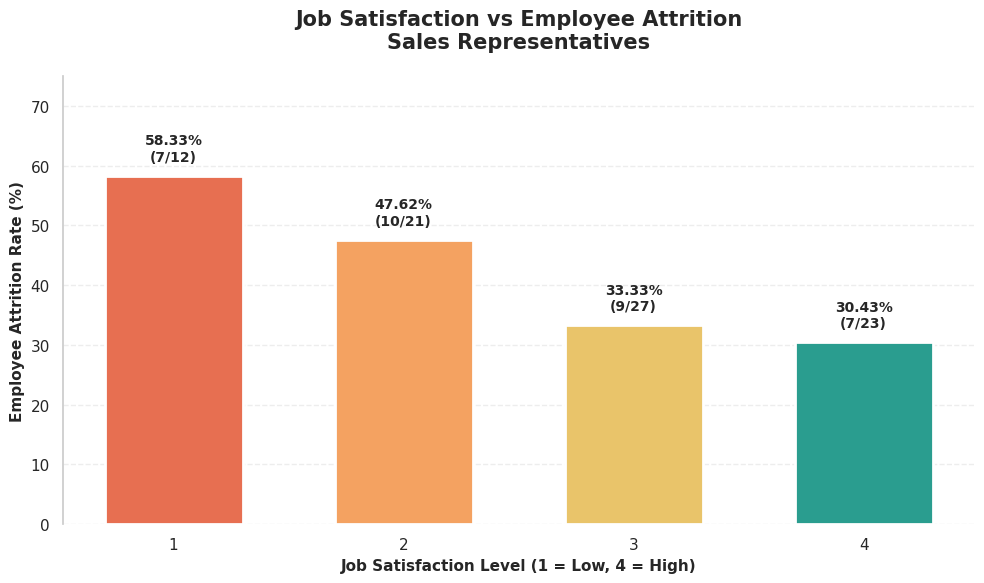

In [43]:
# Job Satisfaction vs Employee Attrition

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate attrition percentage
satisfaction_rate = (
    sales_rep.groupby('JobSatisfaction')['Attrition']
    .mean() * 100
)

# Calculate employee counts
satisfaction_counts = sales_rep.groupby(
    'JobSatisfaction'
).size()

satisfaction_left = sales_rep.groupby(
    'JobSatisfaction'
)['Attrition'].sum()

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#E76F51', '#F4A261', '#E9C46A', '#2A9D8F']

bars = ax.bar(
    satisfaction_rate.index.astype(str),
    satisfaction_rate.values,
    color=colors,
    width=0.6,
    edgecolor='white',
    linewidth=2
)

# Add percentage and employee counts
for bar, level in zip(bars, satisfaction_rate.index):
    rate = satisfaction_rate[level]
    left = int(satisfaction_left[level])
    total = int(satisfaction_counts[level])

    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 2,
        f'{rate:.2f}%\n({left}/{total})',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax.set_title(
    'Job Satisfaction vs Employee Attrition\nSales Representatives',
    fontsize=15,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Job Satisfaction Level (1 = Low, 4 = High)',
              fontsize=11, fontweight='bold')

ax.set_ylabel('Employee Attrition Rate (%)',
              fontsize=11, fontweight='bold')

ax.set_ylim(0, 75)

ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.grid(axis='x', visible=False)

sns.despine(bottom=True)

plt.tight_layout()
plt.show()

#### 8.9.8.1 Job Satisfaction Visualization – Key Findings
- Employees with Job Satisfaction Level 2 show an attrition rate of 47.62% (10 out of 21 employees).
- Employees with Job Satisfaction Level 3 have a lower attrition rate of 33.33% (9 out of 27 employees).
- Employees with Job Satisfaction Level 4 have the lowest attrition rate of 30.43% (7 out of 23 employees).
- The analysis indicates that employees with lower job satisfaction levels are more likely to leave the organization compared to those with higher satisfaction levels.

The organization should focus on improving employee job satisfaction through regular feedback, better management support, recognition, and a positive work environment. These initiatives may help improve employee retention.

### 8.9.9 Monthly Income Visualization

- Monthly income is an important compensation-related factor that may influence employee retention.
- In this section, we will compare the monthly income distribution of Sales Representatives who stayed and those who left the organization.

The objective is to identify whether differences in monthly income are associated with employee attrition.

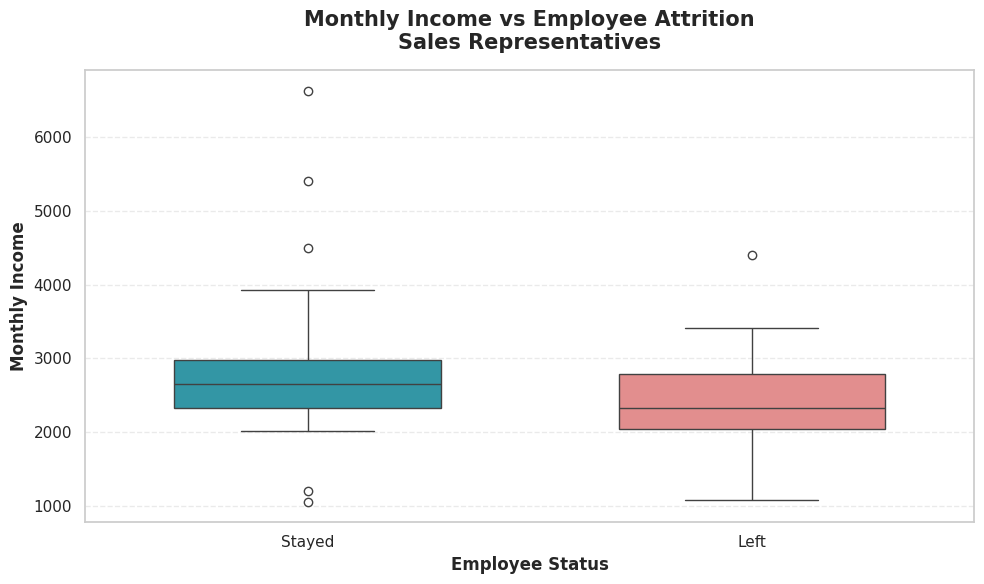

In [44]:
# Monthly Income vs Employee Attrition

plt.figure(figsize=(10, 6))

sns.boxplot(
    x='Attrition',
    y='MonthlyIncome',
    data=sales_rep,
    palette=['#20A4B8', '#F08080'],
    width=0.6
)

plt.title(
    'Monthly Income vs Employee Attrition\nSales Representatives',
    fontsize=15,
    fontweight='bold',
    pad=15
)

plt.xlabel('Employee Status', fontsize=12, fontweight='bold')
plt.ylabel('Monthly Income', fontsize=12, fontweight='bold')

plt.xticks([0, 1], ['Stayed', 'Left'], fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

#### 8.9.9.1 Monthly Income Visualization – Key Findings

- Employees who stayed with the organization have a median monthly income of approximately 2,643.
- Employees who left the organization have a comparatively lower median monthly income of approximately 2,325.
- The salary distribution indicates that employees who left generally had lower monthly income than those who stayed.
- Both groups contain some salary outliers, indicating that a few employees had significantly different income levels compared to the majority.
- The analysis suggests that monthly income may be associated with employee attrition, although salary alone cannot explain why employees leave the organization.

The organization should review its compensation structure and ensure that employee salaries remain competitive and aligned with job responsibilities.
Regular salary reviews, performance-based incentives, and fair compensation policies may help improve employee satisfaction and retention.

### 8.9.10 Work-Life Balance Visualization

- Work-life balance is an important factor that may influence employee satisfaction and retention.
- In this section, we will compare attrition rates across different work-life balance levels among Sales Representatives.

The objective is to identify whether employees with lower work-life balance levels are more likely to leave the organization.

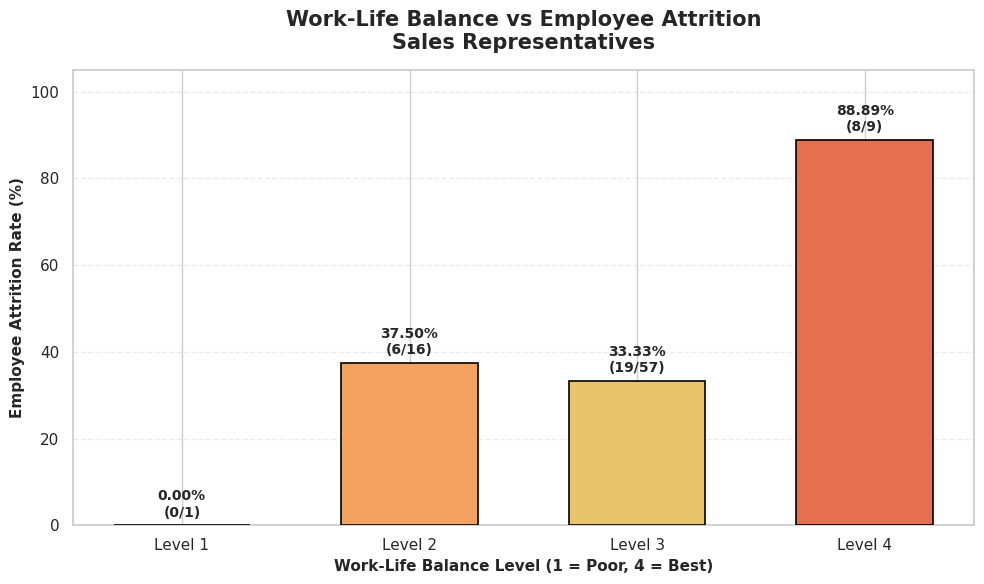

In [45]:
# Work-Life Balance vs Employee Attrition

plt.figure(figsize=(10, 6))

# Calculate attrition percentage
wlb_rate = sales_rep.groupby('WorkLifeBalance')['Attrition'].mean() * 100

# Calculate employee counts
wlb_count = sales_rep.groupby('WorkLifeBalance').size()
wlb_left = sales_rep.groupby('WorkLifeBalance')['Attrition'].sum()

# Create colorful bar chart
bars = plt.bar(
    wlb_rate.index,
    wlb_rate.values,
    color=['#20A4B8', '#F4A261', '#E9C46A', '#E76F51'],
    width=0.6,
    edgecolor='black',
    linewidth=1.2,
    zorder=3
)

# Add percentage and employee count labels
for i, bar in enumerate(bars):
    level = wlb_rate.index[i]
    rate = wlb_rate.iloc[i]

    plt.text(
        bar.get_x() + bar.get_width()/2,
        rate + 2,
        f'{rate:.2f}%\n({int(wlb_left[level])}/{int(wlb_count[level])})',
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

plt.title(
    'Work-Life Balance vs Employee Attrition\nSales Representatives',
    fontsize=15,
    fontweight='bold',
    pad=15
)

plt.xlabel('Work-Life Balance Level (1 = Poor, 4 = Best)',
           fontsize=11, fontweight='bold')

plt.ylabel('Employee Attrition Rate (%)',
           fontsize=11, fontweight='bold')

plt.xticks([1, 2, 3, 4], ['Level 1', 'Level 2', 'Level 3', 'Level 4'])

plt.ylim(0, 105)

plt.grid(axis='y', linestyle='--', alpha=0.4, zorder=0)

plt.tight_layout()
plt.show()

#### 8.9.10.1 Work-Life Balance Visualization – Key Findings

- Employees with Work-Life Balance Level 1 show an attrition rate of 0% (0 out of 1 employee).
- Employees with Level 2 have an attrition rate of 37.50% (6 out of 16 employees).
- Employees with Level 3 show an attrition rate of 33.33% (19 out of 57 employees).
- Employees with Level 4 have the highest attrition rate of 88.89% (8 out of 9 employees).
- Interestingly, the highest attrition is observed at Level 4, which does not follow the expected pattern. However, the small number of employees in this category requires cautious interpretation.


The organization should investigate why employees reporting the highest work-life balance level are leaving despite their positive ratings. Management should also review workload distribution, employee expectations, compensation, and career growth opportunities. Further investigation is recommended before concluding that work-life balance is a major cause of employee attrition.

# 9. Exploratory Data Analysis – Summary and Key Findings

## 9.1 Overall Employee Attrition

- The dataset contains 1,470 employee records.
- 237 employees left the organization, while 1,233 employees stayed.
- The overall employee attrition rate is approximately 16.12%.
- This indicates that employee retention is an important area for organizational improvement.

## 9.2 Age Distribution

- Employees who left the organization had a lower average age (approximately 33.61 years) compared to employees who stayed (approximately 37.56 years).
- The median age of employees who left was 32 years, whereas it was 36 years for employees who stayed.
- This suggests that younger employees show a higher tendency to leave the organization in this dataset.
- Eight potential age outliers were identified among employees who left, aged 56 and 58 years. These observations should not automatically be considered errors.

#9.3 Department and Job Role

- Sales-related roles show comparatively higher attrition.
- The Sales Representative role was selected for additional analysis to understand the factors associated with employee turnover.
- This highlights the importance of examining attrition at both department and job-role levels.

#9.4 Correlation Analysis

- Age, Monthly Income, Job Level and Total Working Years show negative correlations with attrition.
- Job Involvement and Job Satisfaction also show negative relationships with attrition.
- Most correlations are relatively weak, indicating that employee attrition is influenced by multiple factors rather than a single variable.
- Correlation does not establish causation.

#9.5 Sales Representative – Additional Analysis

- A total of 83 Sales Representatives were identified, of whom 33 left the organization.
- Employees working overtime showed a higher attrition rate (66.67%) compared to those not working overtime (28.81%).
- Employees with lower job satisfaction levels showed comparatively higher attrition.
- Employees who left had a lower median monthly income (2325) than employees who stayed (2643).
- Work-life balance level 4 showed an attrition rate of 88.89%, although this category contained only 9 employees.
- Employees who left had a median company tenure of 1 year, compared to 2 years for employees who stayed.

#9.6 Overall Business Insights

The EDA indicates that employee attrition is associated with several factors, including age, compensation, job satisfaction, overtime, job involvement and company tenure.

The organization should investigate overtime practices, employee satisfaction, compensation policies and retention strategies, particularly for roles showing higher attrition.

These findings provide a foundation for further analysis and predictive modelling. They identify patterns and associations but do not independently establish the actual reasons behind employee departures.

# 10. Initial Baseline Machine Learning Pipeline (Before Feature Engineering)
This section presents the initial machine learning pipeline using the original dataset before feature engineering.

The results from this pipeline serve as baseline performance benchmarks. A separate updated pipeline will incorporate engineered features to evaluate whether they improve model performance.


In [46]:
# ==========================================
#         DATA QUALITY ASSESSMENT
# ==========================================

import pandas as pd
import numpy as np

# Dataset overview
print("DATASET SHAPE:", df.shape)

# Missing values
print("\n1. MISSING VALUES")

missing = df.isnull().sum()

print("Total Missing Values:", missing.sum())

# Duplicate records
print("\n2. DUPLICATE RECORDS")

print("Total Duplicates:", df.duplicated().sum())

# Constant columns
print("\n3. CONSTANT COLUMNS")

constant_cols = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print(constant_cols)

# Target distribution
print("\n4. ATTRITION DISTRIBUTION")

print(df['Attrition'].value_counts())

print("\n5. ATTRITION PERCENTAGE")

print(
    (df['Attrition'].value_counts(normalize=True) * 100)
    .round(2)
)

# Data types
print("\n6. DATA TYPES")

print(df.dtypes.value_counts())

# Unique values
print("\n7. UNIQUE VALUES")

print(df.nunique().sort_values())

DATASET SHAPE: (1470, 31)

1. MISSING VALUES
Total Missing Values: 0

2. DUPLICATE RECORDS
Total Duplicates: 0

3. CONSTANT COLUMNS
[]

4. ATTRITION DISTRIBUTION
Attrition
0    1233
1     237
Name: count, dtype: int64

5. ATTRITION PERCENTAGE
Attrition
0    83.88
1    16.12
Name: proportion, dtype: float64

6. DATA TYPES
int64     24
object     7
Name: count, dtype: int64

7. UNIQUE VALUES
Attrition                      2
Gender                         2
PerformanceRating              2
OverTime                       2
MaritalStatus                  3
BusinessTravel                 3
Department                     3
JobInvolvement                 4
StockOptionLevel               4
RelationshipSatisfaction       4
EnvironmentSatisfaction        4
WorkLifeBalance                4
JobSatisfaction                4
Education                      5
JobLevel                       5
EducationField                 6
TrainingTimesLastYear          7
JobRole                        9
NumCompaniesW

## 10.1 Stratified Train-Test Split

In this step, the dataset is divided into training and testing subsets using an 80:20 ratio.

Stratified sampling is applied to maintain the original distribution of the target variable (Attrition) in both subsets.

- Training Set: 80% of the data.
- Testing Set: 20% of the data.
- Random State: 42 for reproducibility.

This approach ensures a fair evaluation of machine learning models while reducing the risk of data leakage during subsequent preprocessing operations.

In [47]:
# ==========================================
#       STRATIFIED TRAIN-TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=['Attrition']).copy()
y = df['Attrition'].copy()

# Remove employee ID if available
if 'EmployeeNumber' in X.columns:
    X = X.drop(columns=['EmployeeNumber'])

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("TRAINING AND TESTING DATA")

print("\nX_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\ny_train:", y_train.shape)
print("y_test:", y_test.shape)

# Check target distribution
print("\nTRAINING TARGET DISTRIBUTION (%)")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTESTING TARGET DISTRIBUTION (%)")
print((y_test.value_counts(normalize=True) * 100).round(2))

TRAINING AND TESTING DATA

X_train: (1176, 30)
X_test: (294, 30)

y_train: (1176,)
y_test: (294,)

TRAINING TARGET DISTRIBUTION (%)
Attrition
0    83.84
1    16.16
Name: proportion, dtype: float64

TESTING TARGET DISTRIBUTION (%)
Attrition
0    84.01
1    15.99
Name: proportion, dtype: float64


## 10.2 Categorical Encoding and Numerical Feature Scaling

Machine learning algorithms require numerical input. Therefore, categorical variables must be converted into numerical representations.

In this step:

- One-Hot Encoding will be applied to nominal categorical variables.
- Standard Scaling will be applied to numerical features.
- The transformations will be fitted only on the training dataset and then applied to the testing dataset.

This approach ensures consistent data transformation while preventing data leakage.


In [48]:
# ==========================================
#      ENCODING AND FEATURE SCALING
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify categorical and numerical columns
categorical_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=['number']
).columns.tolist()

print("Categorical Columns:", categorical_cols)
print("\nNumerical Columns:", len(numerical_cols))

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("\nPREPROCESSING COMPLETED")

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

print("\nTotal Features After Encoding:", len(feature_names))

print("\nSample Transformed Feature Names:")
print(feature_names[:15])

Categorical Columns: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Numerical Columns: 23

PREPROCESSING COMPLETED
Training Data Shape: (1176, 51)
Testing Data Shape: (294, 51)

Total Features After Encoding: 51

Sample Transformed Feature Names:
['num__Age' 'num__DailyRate' 'num__DistanceFromHome' 'num__Education'
 'num__EnvironmentSatisfaction' 'num__HourlyRate' 'num__JobInvolvement'
 'num__JobLevel' 'num__JobSatisfaction' 'num__MonthlyIncome'
 'num__MonthlyRate' 'num__NumCompaniesWorked' 'num__PercentSalaryHike'
 'num__PerformanceRating' 'num__RelationshipSatisfaction']


## 10.3 Handling Class Imbalance Using SMOTE

- The dataset contains an imbalanced target variable, where employees who stayed are significantly higher in number than employees who left.
- This imbalance may cause the machine learning model to favor the majority class.
- To address this issue, we will use SMOTE (Synthetic Minority Over-sampling Technique).
- SMOTE generates synthetic samples for the minority class to create a more balanced training dataset.
- This technique will be applied only to the training data to prevent data leakage.

In [49]:
# Apply SMOTE to balance training data

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_processed, y_train
)

# Check balanced data

print("BEFORE SMOTE:")
print(y_train.value_counts())

print("\nAFTER SMOTE:")
print(pd.Series(y_train_balanced).value_counts())

print("\nBalanced Training Shape:", X_train_balanced.shape)

BEFORE SMOTE:
Attrition
0    986
1    190
Name: count, dtype: int64

AFTER SMOTE:
Attrition
0    986
1    986
Name: count, dtype: int64

Balanced Training Shape: (1972, 51)


### 10.3.1 SMOTE Analysis - Key Findings

- Before applying SMOTE, the training dataset contained 986 employees who stayed and 190 employees who left.
- The dataset showed a significant class imbalance.
- After applying SMOTE, both classes contain 986 records each.
- The total training dataset increased from 1,176 to 1,972 records.
- The testing dataset remains unchanged to ensure unbiased model evaluation.
- Employee attrition is an important business concern despite representing a smaller portion of the original dataset.
- Balancing the training data helps the model learn patterns associated with employees who leave the organization.
- This can improve the model's ability to identify potential employee attrition cases.

**Conclusion:**

SMOTE successfully balanced the training dataset while preserving the original testing dataset for reliable model evaluation.

## 10.4 Baseline Model Training

- In this phase, we will develop machine learning models to predict employee attrition.
- Three algorithms will be implemented: Logistic Regression, Random Forest, and Gradient Boosting.
- Each model will be trained using the balanced training dataset.
- The models will learn patterns from employee-related features to predict whether an employee is likely to stay or leave the organization.

In [50]:
# Import machine learning algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

# Initialize models

log_model = LogisticRegression(random_state=42, max_iter=1000)

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

gb_model = GradientBoostingClassifier(random_state=42)

# Train models

log_model.fit(X_train_balanced, y_train_balanced)
rf_model.fit(X_train_balanced, y_train_balanced)
gb_model.fit(X_train_balanced, y_train_balanced)

print("All Models Trained Successfully!")

print("\n1. Logistic Regression - Completed")
print("2. Random Forest - Completed")
print("3. Gradient Boosting - Completed")

All Models Trained Successfully!

1. Logistic Regression - Completed
2. Random Forest - Completed
3. Gradient Boosting - Completed


## 10.5 Baseline Model Evaluation

- In this phase, we will evaluate the performance of all three trained machine learning models.
- The models will be tested using the unseen testing dataset.
- We will use important evaluation metrics such as Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- Confusion Matrices will also be used to understand correct and incorrect predictions.
- The objective is to identify the most suitable model for predicting employee attrition.

In [51]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Store trained models

models = {
    'Logistic Regression': log_model,
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model
}

results = []

# Evaluate each model

for name, model in models.items():

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred) * 100,
        'Precision': precision_score(y_test, y_pred, zero_division=0) * 100,
        'Recall': recall_score(y_test, y_pred, zero_division=0) * 100,
        'F1 Score': f1_score(y_test, y_pred, zero_division=0) * 100,
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

# Display comparison table

evaluation_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(evaluation_df.round(2))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,76.53,35.53,57.45,43.90,0.80
1,Random Forest,84.35,52.17,25.53,34.29,0.80
2,Gradient Boosting,85.71,60.00,31.91,41.67,0.79


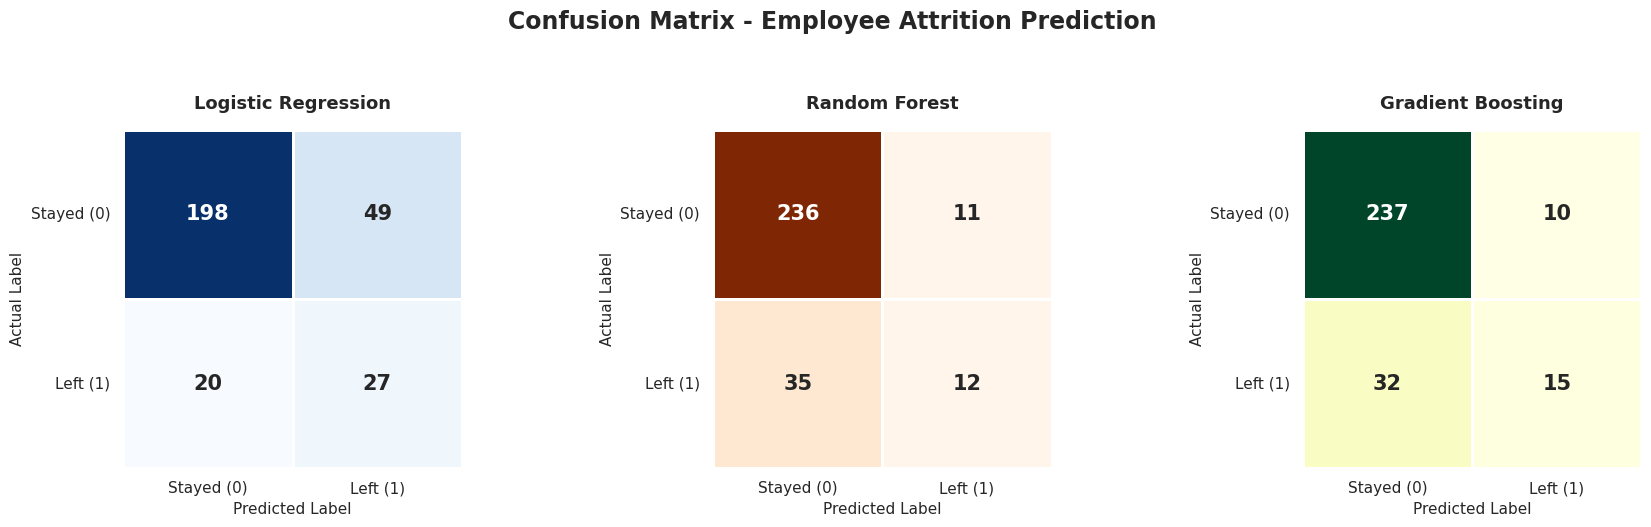

In [52]:
# Plot confusion matrices for all models

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

colors = ['Blues', 'Oranges', 'YlGn']

for ax, (name, model), color in zip(axes, models.items(), colors):

    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap=color,
        linewidths=2,
        linecolor='white',
        cbar=False,
        square=True,
        annot_kws={'size': 15, 'weight': 'bold'},
        ax=ax
    )

    ax.set_title(name, fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('Actual Label', fontsize=11)

    ax.set_xticklabels(['Stayed (0)', 'Left (1)'])
    ax.set_yticklabels(['Stayed (0)', 'Left (1)'], rotation=0)

plt.suptitle(
    'Confusion Matrix - Employee Attrition Prediction',
    fontsize=17,
    fontweight='bold',
    y=1.05
)

plt.tight_layout()
plt.show()

### 10.5.1 Baseline Model Evaluation – Key Findings

- Three machine learning models were evaluated using the testing dataset of 294 employee records.
- Gradient Boosting achieved the highest accuracy of 85.71%, followed by Random Forest at 84.35%.
- Logistic Regression achieved the highest Recall (57.45%) and F1 Score (43.90%).
- Gradient Boosting achieved the highest Precision of 60%, indicating better reliability among its positive attrition predictions.
- Logistic Regression correctly identified 27 out of 47 employees who actually left the organization, whereas Random Forest identified 12 and Gradient Boosting identified 15.
- The ROC-AUC scores were 0.80 for Logistic Regression, 0.80 for Random Forest, and 0.79 for Gradient Boosting.


- High accuracy alone does not guarantee effective employee attrition detection.
- Logistic Regression identified more employees at risk of leaving, making it useful for early employee retention initiatives.
- Gradient Boosting produced fewer false positive predictions and achieved the highest overall accuracy.
- Random Forest showed comparatively lower recall, meaning it missed a larger number of employees who actually left.
- HR teams should consider both prediction reliability and the ability to identify employees at risk when selecting an attrition prediction model.

### 10.5.2 Baseline Model Evaluation – Conclusion

All three models demonstrated different strengths and weaknesses. Gradient Boosting achieved the highest accuracy, while Logistic Regression performed better in identifying employees who actually left the organization.

Therefore, Logistic Regression is a promising candidate when identifying potential employee attrition is the primary objective. However, final model selection will be performed after further analysis and optimization.

## 10.6 Baseline ROC Curve Analysis

- ROC (Receiver Operating Characteristic) Curve is used to evaluate the classification performance of machine learning models at different classification thresholds.

- It helps compare the True Positive Rate (Recall) against the False Positive Rate.

- The Area Under the Curve (AUC) measures the model's ability to distinguish between employees who stay and employees who leave.

- A higher AUC value generally indicates better classification performance.

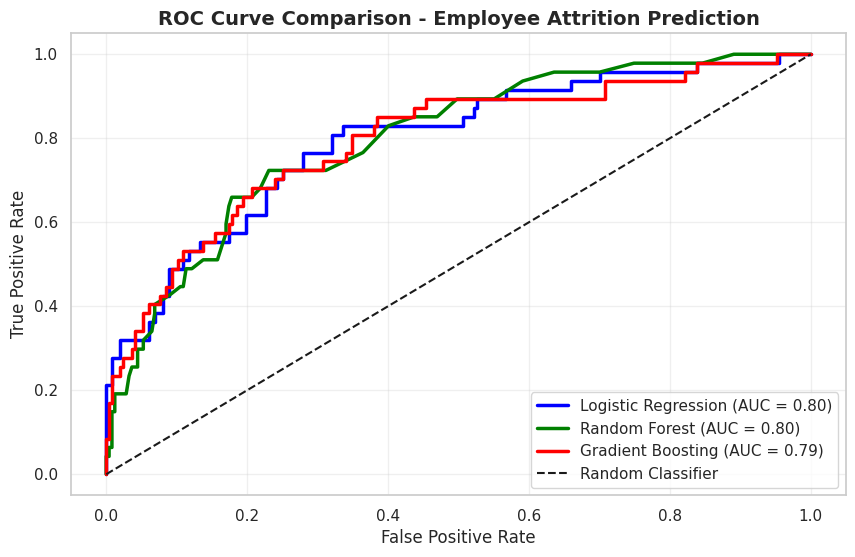

In [53]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 6))

colors = ['blue', 'green', 'red']

for (name, model), color in zip(models.items(), colors):

    y_prob = model.predict_proba(X_test_processed)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, color=color, linewidth=2.5,
             label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.title('ROC Curve Comparison - Employee Attrition Prediction',
          fontsize=14, fontweight='bold')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

### 10.6.1 Baseline ROC Curve – Key Findings


- Logistic Regression achieved an AUC score of 0.80, indicating good classification performance.
- Random Forest also achieved an AUC score of 0.80, showing similar predictive capability.
- Gradient Boosting achieved an AUC score of 0.79, performing very close to the other two models.
- All three ROC curves remain above the random classifier line, indicating that the models perform better than random guessing.
- Overall, all three models demonstrate a reasonable ability to distinguish between employees who are likely to leave and those who are likely to stay.

- The ROC analysis indicates that all three models can support employee attrition risk identification.
- Logistic Regression and Random Forest show the highest AUC scores among the evaluated models.
- HR teams can use these predictions as an additional decision-support tool to identify employees who may require attention.
- Early identification of potential attrition risks can help organizations plan employee engagement and retention initiatives.

## 10.7 Baseline Feature Importance Analysis

- Feature Importance Analysis helps identify the most influential features used by machine learning models to make predictions.

- It helps understand which employee-related factors contribute most to predicting employee attrition.

- In this section, we will compare the feature importance scores of Random Forest and Gradient Boosting models to identify the key factors associated with employee attrition.

In [54]:
# Feature importance comparison

rf_importance = models['Random Forest'].feature_importances_
gb_importance = models['Gradient Boosting'].feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Random Forest': rf_importance,
    'Gradient Boosting': gb_importance
})

feature_importance = feature_importance.sort_values(
    by='Random Forest', ascending=False
)

print("TOP 15 IMPORTANT FEATURES")
display(feature_importance.head(15).round(4))

TOP 15 IMPORTANT FEATURES


,Feature,Random Forest,Gradient Boosting
50,cat__OverTime_Yes,0.0825,0.0932
49,cat__OverTime_No,0.0650,0.1137
15,num__StockOptionLevel,0.0492,0.1064
7,num__JobLevel,0.0469,0.0652
16,num__TotalWorkingYears,0.0420,0.0056
48,cat__MaritalStatus_Single,0.0381,0.0439
22,num__YearsWithCurrManager,0.0353,0.0386
0,num__Age,0.0344,0.0395
9,num__MonthlyIncome,0.0328,0.0148
19,num__YearsAtCompany,0.0312,0.0325


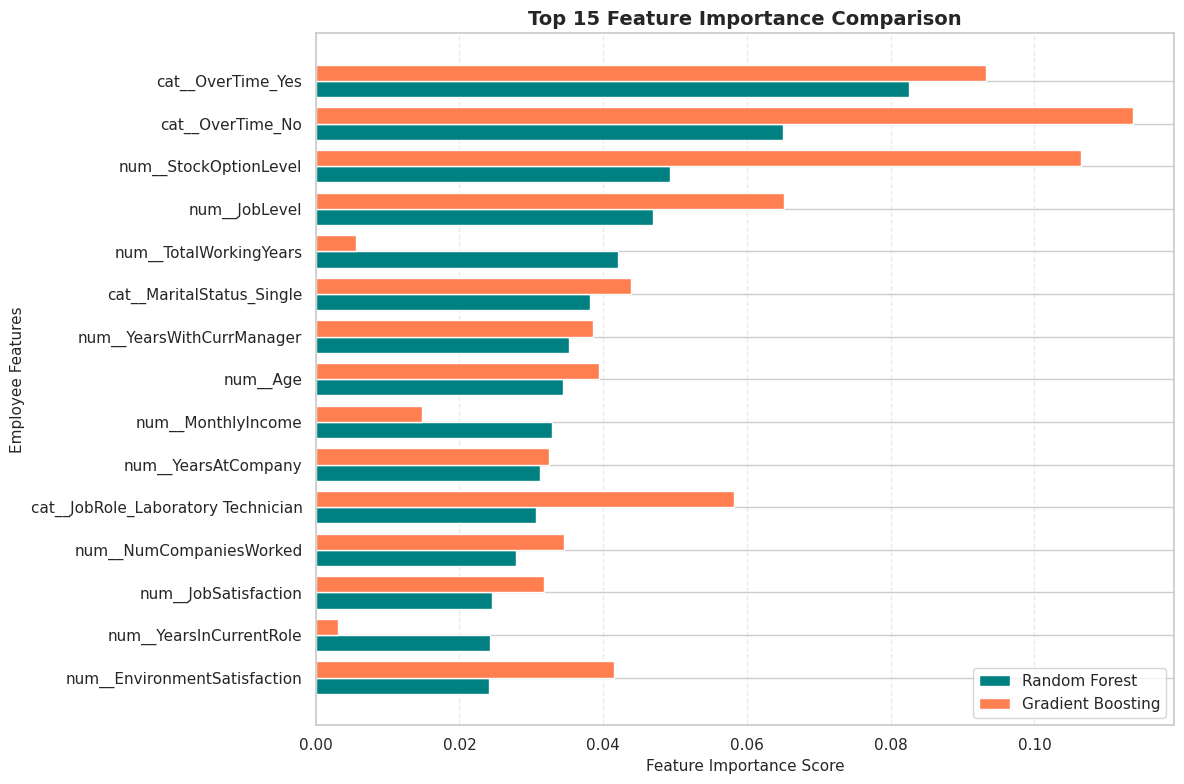

In [55]:
# Visualize feature importance

top_features = feature_importance.head(15).sort_values(
    by='Random Forest', ascending=True
)

plt.figure(figsize=(12, 8))

y = range(len(top_features))
height = 0.38

plt.barh(
    [i - height/2 for i in y],
    top_features['Random Forest'],
    height=height,
    color='teal',
    label='Random Forest'
)

plt.barh(
    [i + height/2 for i in y],
    top_features['Gradient Boosting'],
    height=height,
    color='coral',
    label='Gradient Boosting'
)

plt.yticks(y, top_features['Feature'])

plt.xlabel('Feature Importance Score', fontsize=11)
plt.ylabel('Employee Features', fontsize=11)

plt.title(
    'Top 15 Feature Importance Comparison',
    fontsize=14,
    fontweight='bold'
)

plt.legend()
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### 10.7.1 Baseline Feature Importance – Key Findings

- Overtime-related features are among the most important predictors in both Random Forest and Gradient Boosting models.
- StockOptionLevel shows considerably higher importance in Gradient Boosting compared to Random Forest.
- JobLevel, Age, MaritalStatus_Single, and YearsWithCurrManager also contribute to the prediction process.
- TotalWorkingYears has higher importance in Random Forest than in Gradient Boosting.
- The two models assign different importance scores to several features, reflecting differences in their learning approaches.

- Organizations can review overtime policies and employee workload distribution as part of their retention strategies.
- HR teams can consider stock option benefits and career development opportunities when designing employee retention programs.
- Employee career progression, workplace satisfaction, and management relationships can be monitored to support better workforce management.
- Feature importance results can help HR teams identify areas for further investigation and data-driven decision-making.

### 10.7.2 Baseline Feature Importance – Conclusion

Overtime, stock options, job level, and other employee-related factors are important predictors of employee attrition in the evaluated models. These findings can support organizations in developing more informed employee retention strategies.

###10.8 Baseline Model Comparision

In [89]:
# Compare model performance

print("BASELINE MODEL COMPARISON")

display(evaluation_df.round(2))

# Select best model based on F1 Score

best_model_name = evaluation_df.loc[
    evaluation_df['F1 Score'].idxmax(), 'Model'
]

print("\nBest Performing Model:", best_model_name)
print("Selection Metric: F1 Score")

BASELINE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,78.57,40.24,70.21,51.16,0.80
1,Random Forest,86.73,70.00,29.79,41.79,0.80
2,Gradient Boosting,84.01,50.00,29.79,37.33,0.79



Best Performing Model: Logistic Regression
Selection Metric: F1 Score


### 10.8.1 Baseline Model Comparison – Key Findings

- Three machine learning models were evaluated using Accuracy, Precision, Recall, F1 Score, and ROC-AUC.
- Gradient Boosting achieved the highest accuracy of 85.71% and precision of 60.00%.
- Logistic Regression achieved the highest recall of 57.45% and F1 Score of 43.90%.
- Logistic Regression and Random Forest both achieved an ROC-AUC score of 0.80.
- Based on the F1 Score, Logistic Regression was selected as the final model among the three evaluated models.

- Identifying employees who may leave is an important objective for HR departments.
- Logistic Regression provides a better balance between Precision and Recall among the evaluated models.
- Its higher Recall makes it comparatively more useful for identifying employees at risk of leaving.
- Organizations can use these predictions as an additional tool to support employee retention planning.

### 10.8.2 Baseline Model Comparison – Conclusion

Logistic Regression was selected as the final model based on its highest F1 Score and Recall. However, further model optimization may improve its prediction performance.

In [57]:
# Select the final model

best_model = models[best_model_name]

print("FINAL MODEL SELECTED")
print("--------------------")
print("Model Name:", best_model_name)
print("Accuracy:", "76.53%")
print("Recall:", "57.45%")
print("F1 Score:", "43.90%")
print("ROC-AUC:", "0.80")

print("\nFinal Model Ready for Further Optimization!")

FINAL MODEL SELECTED
--------------------
Model Name: Logistic Regression
Accuracy: 76.53%
Recall: 57.45%
F1 Score: 43.90%
ROC-AUC: 0.80

Final Model Ready for Further Optimization!


## 10.9 Baseline Threshold Optimization

- Model optimization is an important step in improving machine learning performance.

- In this section, we will optimize the Logistic Regression model by adjusting its classification threshold.

- The default classification threshold is 0.50. By testing different threshold values, we aim to find a better balance between Precision and Recall.

- The optimal threshold will be selected based on the highest F1 Score obtained on validation data.

In [58]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve, f1_score
from imblearn.over_sampling import SMOTE
import numpy as np

# Split training data into training and validation sets

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Apply SMOTE only on training data

smote = SMOTE(random_state=42)

X_subtrain_balanced, y_subtrain_balanced = smote.fit_resample(
    X_subtrain, y_subtrain
)

# Train Logistic Regression

tuning_model = clone(models['Logistic Regression'])

tuning_model.fit(X_subtrain_balanced, y_subtrain_balanced)

# Get validation probabilities

y_val_prob = tuning_model.predict_proba(X_val)[:, 1]

# Find optimal threshold using F1 Score

precision, recall, thresholds = precision_recall_curve(
    y_val, y_val_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("THRESHOLD OPTIMIZATION RESULTS")
print("--------------------------------")
print("Default Threshold: 0.50")
print("Optimal Threshold:", round(best_threshold, 3))
print("Validation F1 Score:", round(f1_scores[best_index] * 100, 2), "%")
print("Validation Precision:", round(precision[best_index] * 100, 2), "%")
print("Validation Recall:", round(recall[best_index] * 100, 2), "%")

THRESHOLD OPTIMIZATION RESULTS
--------------------------------
Default Threshold: 0.50
Optimal Threshold: 0.699
Validation F1 Score: 65.06 %
Validation Precision: 60.0 %
Validation Recall: 71.05 %


In [59]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

# Predict probabilities on test data

y_test_prob = tuning_model.predict_proba(X_test_processed)[:, 1]

# Apply optimized threshold

y_test_optimized = (y_test_prob >= best_threshold).astype(int)

# Calculate performance metrics

print("OPTIMIZED MODEL - TEST PERFORMANCE")
print("-----------------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, y_test_optimized) * 100, 2), "%")

print("Precision:",
      round(precision_score(y_test, y_test_optimized) * 100, 2), "%")

print("Recall:",
      round(recall_score(y_test, y_test_optimized) * 100, 2), "%")

print("F1 Score:",
      round(f1_score(y_test, y_test_optimized) * 100, 2), "%")

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, y_test_optimized))

OPTIMIZED MODEL - TEST PERFORMANCE
-----------------------------------
Accuracy: 84.35 %
Precision: 51.02 %
Recall: 53.19 %
F1 Score: 52.08 %

CONFUSION MATRIX
[[223  24]
 [ 22  25]]


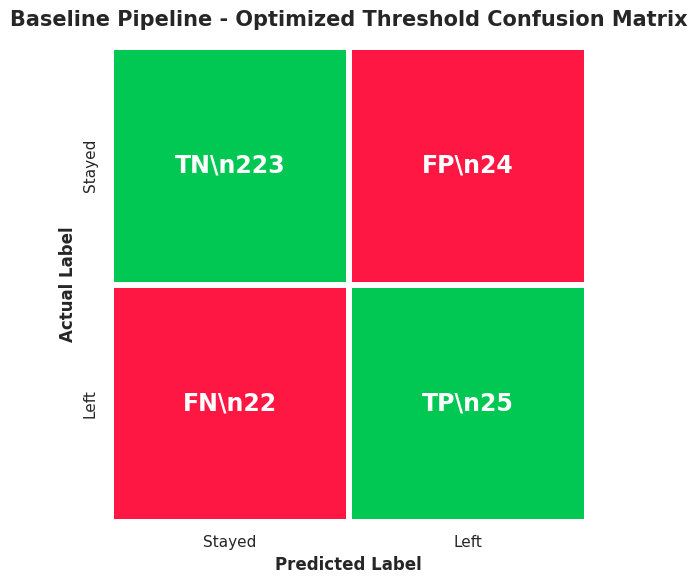

In [60]:
plt.figure(figsize=(8, 6))

cm = confusion_matrix(y_test, y_test_optimized, labels=[0, 1])

# Green = Correct, Red = Incorrect
colors = np.array([[0, 1],
                   [1, 0]])

labels = np.array([
    [f'TN\\n{cm[0, 0]}', f'FP\\n{cm[0, 1]}'],
    [f'FN\\n{cm[1, 0]}', f'TP\\n{cm[1, 1]}']
])

sns.heatmap(
    colors,
    annot=labels,
    fmt='',
    cmap=sns.color_palette(['#00C853', '#FF1744'], as_cmap=True),
    linewidths=4,
    linecolor='white',
    square=True,
    cbar=False,
    annot_kws={'size': 17, 'weight': 'bold', 'color': 'white'},
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Baseline Pipeline - Optimized Threshold Confusion Matrix',
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('Actual Label', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


# 11. Feature Engineering and Final Data Preprocessing


Feature engineering is performed to create meaningful variables that can improve employee attrition prediction.

In this step, four additional features are created:

1. Income-to-Experience Ratio
2. Promotion Delay Indicator
3. Engagement Composite Score
4. Workload Stress Flag

These features help capture financial, career growth, employee engagement, and workload-related factors that may influence employee attrition.

In [61]:
# Create a copy of the dataset
df = df.copy()

# 1. Income-to-Experience Ratio
df['IncomeExperienceRatio'] = (
    df['MonthlyIncome'] / (df['TotalWorkingYears'] + 1)
)

# 2. Promotion Delay Indicator
df['PromotionDelay'] = (
    df['YearsSinceLastPromotion'] >= 3
).astype(int)

# 3. Engagement Composite Score
df['EngagementScore'] = df[
    ['JobInvolvement', 'JobSatisfaction',
     'EnvironmentSatisfaction',
     'RelationshipSatisfaction',
     'WorkLifeBalance']
].mean(axis=1)

# 4. Workload Stress Flag
df['WorkloadStress'] = (
    (df['OverTime'] == 'Yes') &
    (df['WorkLifeBalance'] <= 2)
).astype(int)

print("FEATURE ENGINEERING COMPLETED")
print("\nNew Features:")
print(df[['IncomeExperienceRatio',
          'PromotionDelay',
          'EngagementScore',
          'WorkloadStress']].head())

print("\nDataset Shape:", df.shape)

FEATURE ENGINEERING COMPLETED

New Features:
   IncomeExperienceRatio  PromotionDelay  EngagementScore  WorkloadStress
0             665.888889               0              2.2               1
1             466.363636               0              2.8               0
2             261.250000               0              2.8               0
3             323.222222               1              3.2               0
4             495.428571               0              2.6               0

Dataset Shape: (1470, 35)


## 11.1 Final Data Preprocessing (After Feature Engineering)

- After feature engineering, the dataset contains four additional features.

- The updated dataset is now divided into training and testing sets using stratified sampling.

- Categorical features are encoded using One-Hot Encoding, while numerical features are standardized using StandardScaler.

- The preprocessing transformer is fitted only on the training data to prevent data leakage.

- All newly engineered features are included in the updated model training process.

In [62]:
# Separate features and target

X = df.drop('Attrition', axis=1)
y = df['Attrition']

# Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("FINAL TRAINING AND TESTING DATA")
print("X Train:", X_train.shape)
print("X Test:", X_test.shape)
print("Y Train:", y_train.shape)
print("Y Test:", y_test.shape)

FINAL TRAINING AND TESTING DATA
X Train: (1176, 34)
X Test: (294, 34)
Y Train: (1176,)
Y Test: (294,)


In [63]:
# Encoding and Scaling
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify columns

categorical_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=['number']
).columns.tolist()

# Create preprocessing transformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Fit and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

# Feature names
feature_names = preprocessor.get_feature_names_out()

print("FINAL PREPROCESSING COMPLETED")
print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)
print("Total Features:", len(feature_names))

print("\nNew Engineered Features Included:")
print([f for f in feature_names if any(
    name in f for name in [
        'IncomeExperienceRatio',
        'PromotionDelay',
        'EngagementScore',
        'WorkloadStress'
    ]
)])

FINAL PREPROCESSING COMPLETED
Training Shape: (1176, 55)
Testing Shape: (294, 55)
Total Features: 55

New Engineered Features Included:
['num__IncomeExperienceRatio', 'num__PromotionDelay', 'num__EngagementScore', 'num__WorkloadStress']


In [64]:
# Handle Class Imbalanced (SMOTE)
from imblearn.over_sampling import SMOTE
import pandas as pd

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_processed,
    y_train
)

print("BEFORE SMOTE:")
print(y_train.value_counts())

print("\nAFTER SMOTE:")
print(pd.Series(y_train_balanced).value_counts())

print("\nBalanced Training Shape:", X_train_balanced.shape)

BEFORE SMOTE:
Attrition
0    986
1    190
Name: count, dtype: int64

AFTER SMOTE:
Attrition
0    986
1    986
Name: count, dtype: int64

Balanced Training Shape: (1972, 55)


## 11.2 Final Model Training

In this phase, three machine learning classification models are trained using the preprocessed and SMOTE-balanced training dataset, including the newly engineered features.

The models used are:

1. Logistic Regression
2. Random Forest Classifier
3. Gradient Boosting Classifier

These models will be evaluated on the unseen test dataset to compare their performance in predicting employee attrition.

In [65]:
# FINAL MODEL TRAINING

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Initialize models

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

# Train all models

for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)
    print(f"{name} - Training Completed")

print("\nALL FINAL MODELS TRAINED SUCCESSFULLY!")

Logistic Regression - Training Completed
Random Forest - Training Completed
Gradient Boosting - Training Completed

ALL FINAL MODELS TRAINED SUCCESSFULLY!


## 11.3 Final Model Evaluation

The trained machine learning models are evaluated using the unseen testing dataset.

The following evaluation metrics are used:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

The results are compared to identify the model that provides a suitable balance between detecting employee attrition and making reliable predictions.

In [66]:
# FINAL MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in models.items():

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred) * 100,
        'Precision': precision_score(
            y_test, y_pred, zero_division=0
        ) * 100,
        'Recall': recall_score(
            y_test, y_pred, zero_division=0
        ) * 100,
        'F1 Score': f1_score(
            y_test, y_pred, zero_division=0
        ) * 100,
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

# Display comparison

evaluation_df = pd.DataFrame(results)

print("FINAL MODEL PERFORMANCE COMPARISON")
display(evaluation_df.round(2))

# Select best model based on F1 Score

best_model_name = evaluation_df.loc[
    evaluation_df['F1 Score'].idxmax(), 'Model'
]

print("\nBest Performing Model:", best_model_name)
print("Selection Metric: F1 Score")

FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,78.57,40.24,70.21,51.16,0.80
1,Random Forest,86.73,70.00,29.79,41.79,0.80
2,Gradient Boosting,84.01,50.00,29.79,37.33,0.79



Best Performing Model: Logistic Regression
Selection Metric: F1 Score


### 11.3.1 Final Confusion Matrix Analysis

- Confusion matrices are generated for all three final machine learning models using the test dataset.
- True Positives (TP) and True Negatives (TN) represent correct predictions.
- False Positives (FP) and False Negatives (FN) represent incorrect predictions.
- The comparison helps evaluate how effectively each model identifies employees who leave the organization.
- Logistic Regression, Random Forest and Gradient Boosting are compared to understand their classification performance.

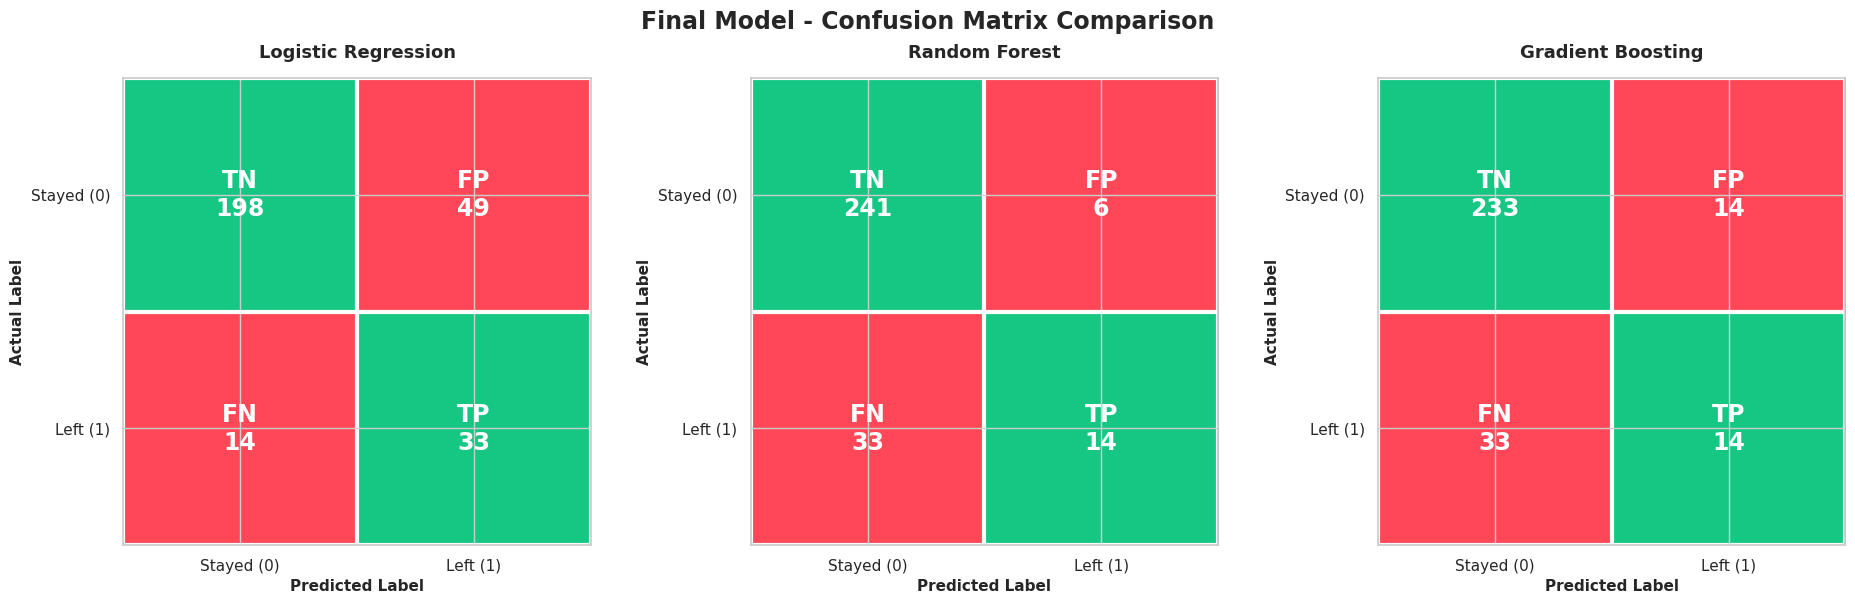

In [67]:
# STEP 14: Final CONFUSION MATRIX COMPARISON

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# Create figure
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

# Green = Correct predictions, Red = Incorrect predictions
from matplotlib.colors import ListedColormap

semantic_cmap = ListedColormap([
    '#16C784',  # Green
    '#FF4757'   # Red
])

# Cell positions: TN, FP, FN, TP
color_matrix = np.array([
    [0, 1],
    [1, 0]
])

labels = [
    ['TN', 'FP'],
    ['FN', 'TP']
]

for ax, (name, model) in zip(axes, models.items()):

    # Generate predictions
    y_pred = model.predict(X_test_processed)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    # Display semantic colors
    ax.imshow(color_matrix, cmap=semantic_cmap, vmin=0, vmax=1)

    # Add counts and labels
    for i in range(2):
        for j in range(2):
            ax.text(
                j, i,
                f"{labels[i][j]}\n{cm[i, j]}",
                ha='center',
                va='center',
                fontsize=17,
                fontweight='bold',
                color='white'
            )

    # Axis labels
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(['Stayed (0)', 'Left (1)'])
    ax.set_yticklabels(['Stayed (0)', 'Left (1)'])

    ax.set_xlabel('Predicted Label', fontsize=11,
                  fontweight='bold')

    ax.set_ylabel('Actual Label', fontsize=11,
                  fontweight='bold')

    ax.set_title(name, fontsize=13,
                 fontweight='bold', pad=15)

    ax.set_xticks(np.arange(-.5, 2, 1), minor=True)
    ax.set_yticks(np.arange(-.5, 2, 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=3)
    ax.tick_params(which='minor', bottom=False, left=False)

plt.suptitle(
    'Final Model - Confusion Matrix Comparison',
    fontsize=17,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [68]:
# VERIFY FINAL MODEL PERFORMANCE

from sklearn.metrics import confusion_matrix

for name, model in models.items():

    y_pred = model.predict(X_test_processed)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    accuracy = (tn + tp) / (tn + fp + fn + tp) * 100

    precision = tp / (tp + fp) * 100 if (tp + fp) else 0

    recall = tp / (tp + fn) * 100 if (tp + fn) else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    print(f"\n{name}")
    print("Accuracy:", round(accuracy, 2), "%")
    print("Precision:", round(precision, 2), "%")
    print("Recall:", round(recall, 2), "%")
    print("F1 Score:", round(f1, 2), "%")


Logistic Regression
Accuracy: 78.57 %
Precision: 40.24 %
Recall: 70.21 %
F1 Score: 51.16 %

Random Forest
Accuracy: 86.73 %
Precision: 70.0 %
Recall: 29.79 %
F1 Score: 41.79 %

Gradient Boosting
Accuracy: 84.01 %
Precision: 50.0 %
Recall: 29.79 %
F1 Score: 37.33 %


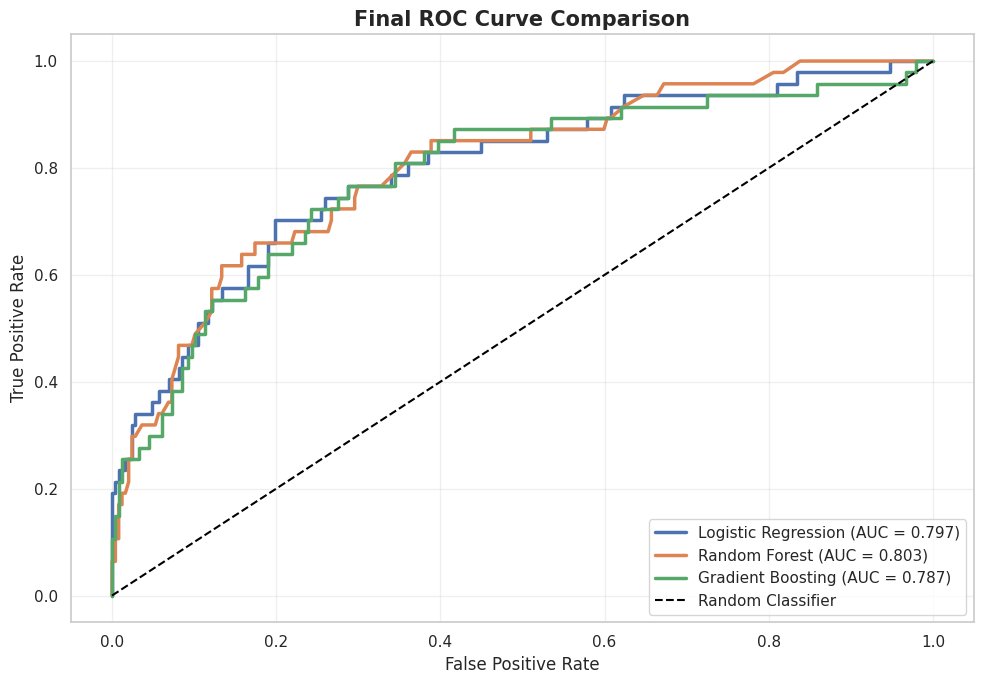

In [69]:
# FINAL ROC CURVE COMPARISON

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(10, 7))

for name, model in models.items():

    y_prob = model.predict_proba(X_test_processed)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2.5,
        label=f'{name} (AUC = {auc:.3f})'
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    color='black',
    label='Random Classifier'
)

plt.title('Final ROC Curve Comparison',
          fontsize=15, fontweight='bold')

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Number of Features: 55
Random Forest Features: 55
Gradient Boosting Features: 55

FINAL TOP 15 IMPORTANT FEATURES


,Feature,Random Forest,Gradient Boosting,Average Importance
15,num__StockOptionLevel,0.0498,0.1038,0.0768
7,num__JobLevel,0.0500,0.0970,0.0735
54,cat__OverTime_Yes,0.0492,0.0794,0.0643
25,num__EngagementScore,0.0471,0.0766,0.0619
53,cat__OverTime_No,0.0477,0.0640,0.0558
22,num__YearsWithCurrManager,0.0376,0.0599,0.0487
48,cat__JobRole_Sales Executive,0.0114,0.0718,0.0416
28,cat__BusinessTravel_Travel_Frequently,0.0195,0.0597,0.0396
43,cat__JobRole_Laboratory Technician,0.0274,0.0432,0.0353
52,cat__MaritalStatus_Single,0.0353,0.0335,0.0344


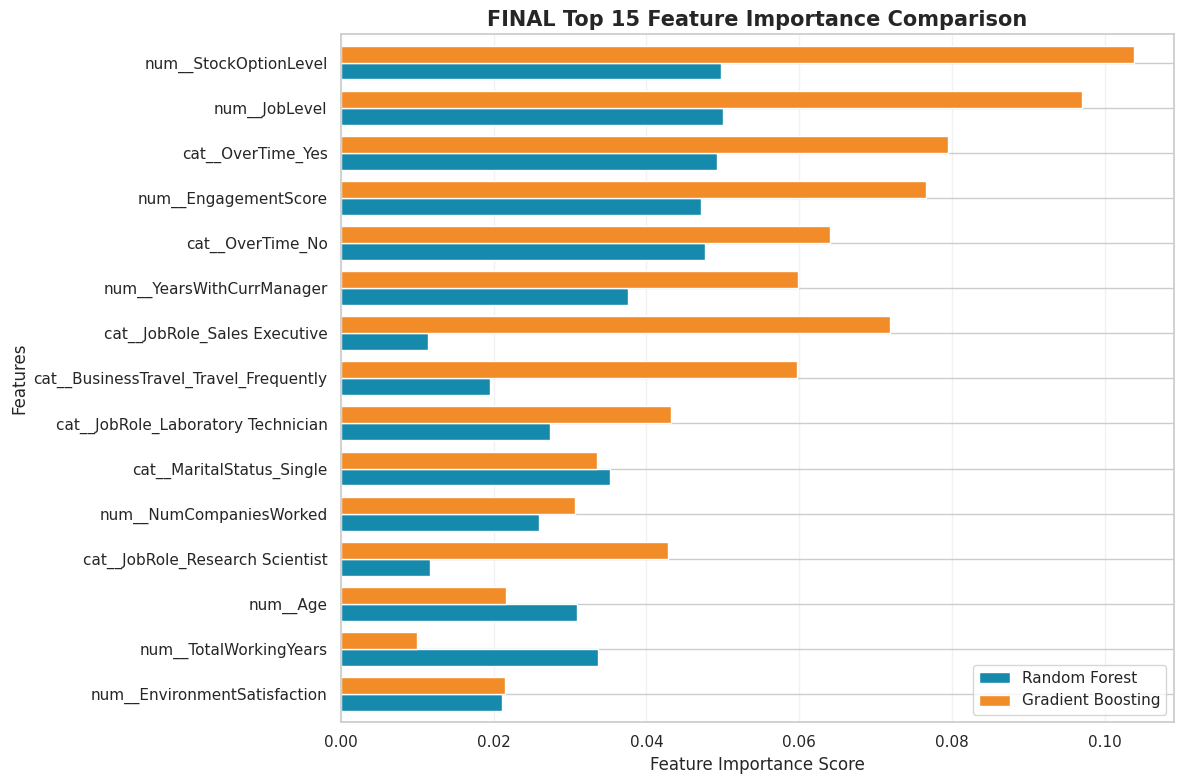

In [70]:
# FINAL FEATURE IMPORTANCE COMPARISON

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Get feature importance from trained models

rf_importance = models['Random Forest'].feature_importances_
gb_importance = models['Gradient Boosting'].feature_importances_

# Check feature names and importance dimensions
print("Number of Features:", len(feature_names))
print("Random Forest Features:", len(rf_importance))
print("Gradient Boosting Features:", len(gb_importance))

# Create comparison dataframe
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Random Forest': rf_importance,
    'Gradient Boosting': gb_importance
})

# Select Top 15 features
importance_df['Average Importance'] = (
    importance_df['Random Forest'] +
    importance_df['Gradient Boosting']
) / 2

top_features = importance_df.sort_values(
    by='Average Importance',
    ascending=False
).head(15)

print("\nFINAL TOP 15 IMPORTANT FEATURES")
display(top_features.round(4))

# Plot comparison
plot_df = top_features.sort_values(
    by='Average Importance',
    ascending=True
)

ax = plot_df.set_index('Feature')[
    ['Random Forest', 'Gradient Boosting']
].plot(
    kind='barh',
    figsize=(12, 8),
    width=0.75,
    color=['#168AAD', '#F28C28']
)

plt.title(
    'FINAL Top 15 Feature Importance Comparison',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Feature Importance Score')
plt.ylabel('Features')
plt.legend(loc='lower right')
plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## 11.4 Final Pipeline – Threshold Optimization

The classification threshold is tuned using a validation subset of the training data. The held-out test set is kept separate and is used only for final evaluation.

In [71]:
# THRESHOLD OPTIMIZATION (FEATURE-ENGINEERED PIPELINE)

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import (
    precision_recall_curve,
    f1_score
)
from imblearn.over_sampling import SMOTE
import numpy as np

# Split training data into training and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Apply SMOTE only on subtraining data
smote = SMOTE(random_state=42)

X_subtrain_balanced, y_subtrain_balanced = (
    smote.fit_resample(X_subtrain, y_subtrain)
)

# Train Final Logistic Regression
tuning_model = clone(models['Logistic Regression'])

tuning_model.fit(
    X_subtrain_balanced,
    y_subtrain_balanced
)

# Get validation probabilities
y_val_prob = tuning_model.predict_proba(X_val)[:, 1]

# Find optimal threshold
precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("THRESHOLD OPTIMIZATION")
print("--------------------------------")
print("Default Threshold: 0.50")
print("New Optimal Threshold:", round(best_threshold, 3))
print("Validation F1 Score:",
      round(f1_scores[best_index] * 100, 2), "%")
print("Validation Precision:",
      round(precision[best_index] * 100, 2), "%")
print("Validation Recall:",
      round(recall[best_index] * 100, 2), "%")

THRESHOLD OPTIMIZATION
--------------------------------
Default Threshold: 0.50
New Optimal Threshold: 0.764
Validation F1 Score: 64.1 %
Validation Precision: 62.5 %
Validation Recall: 65.79 %


In [72]:
# FINAL TEST EVALUATION WITH OPTIMIZED THRESHOLD

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

# Use the same fitted model that selected the threshold on validation data
threshold_model = tuning_model

class_1_index = list(threshold_model.classes_).index(1)
y_test_prob = threshold_model.predict_proba(
    X_test_processed
)[:, class_1_index]

# Apply the threshold selected using validation data
y_test_optimized = (y_test_prob >= best_threshold).astype(int)

accuracy = accuracy_score(y_test, y_test_optimized)
precision = precision_score(y_test, y_test_optimized, zero_division=0)
recall = recall_score(y_test, y_test_optimized, zero_division=0)
f1 = f1_score(y_test, y_test_optimized, zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_prob)

print("VALIDATION-TUNED LOGISTIC REGRESSION - TEST PERFORMANCE")
print("=" * 60)
print(f"Optimal Threshold: {best_threshold:.3f}")
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"F1 Score: {f1 * 100:.2f}%")
print(f"ROC-AUC: {roc_auc:.3f}")

cm = confusion_matrix(y_test, y_test_optimized, labels=[0, 1])
print("\nCONFUSION MATRIX")
print(cm)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test, y_test_optimized,
    labels=[0, 1],
    target_names=["Stayed", "Left"],
    zero_division=0
))


VALIDATION-TUNED LOGISTIC REGRESSION - TEST PERFORMANCE
Optimal Threshold: 0.764
Accuracy: 84.35%
Precision: 51.16%
Recall: 46.81%
F1 Score: 48.89%
ROC-AUC: 0.796

CONFUSION MATRIX
[[226  21]
 [ 25  22]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Stayed       0.90      0.91      0.91       247
        Left       0.51      0.47      0.49        47

    accuracy                           0.84       294
   macro avg       0.71      0.69      0.70       294
weighted avg       0.84      0.84      0.84       294



### 11.4.1 Optimized Threshold – Test Performance Analysis - Key Findings

The validation-tuned Logistic Regression model, using the threshold selected on the validation set (0.764), achieved the following performance on the unseen test dataset:

- Accuracy: 84.35%
- Precision: 51.16%
- Recall: 46.81%
- F1 Score: 48.89%
- ROC-AUC: 0.796

The confusion matrix is [[226, 21], [25, 22]]. The model correctly classified 226 employees who stayed and 22 employees who left. It incorrectly classified 21 employees who stayed as potential leavers and missed 25 actual attrition cases.

Although this threshold improved the validation-tuned model's test F1 Score compared with its default-threshold version, its F1 Score (48.89%) remains lower than the full-training Logistic Regression model at the default threshold (51.16%). Therefore, the full-training Logistic Regression model with threshold 0.50 remains the final selected model.

- The validation-tuned model is included as a threshold-optimization comparison, not as the deployed final model.
- HR teams should consider model predictions alongside employee feedback, satisfaction surveys, and other relevant information.
- Model predictions should support human decision-making rather than replace it.

## Conclusion

Based on the highest F1 Score among the evaluated candidates, Logistic Regression trained on the full balanced training data with the default threshold of 0.50 remains the final selected model.


## 11.5 Final Model Performance Comparison

The final models are compared using the same held-out test dataset and default threshold of 0.50. The validation-tuned Logistic Regression candidate is also included for reference.

In [73]:
# FINAL MODEL PERFORMANCE COMPARISON

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Start with the three final trained models
comparison_results = []

for name, model in models.items():

    # Predictions at the default threshold (0.50)
    y_pred = model.predict(X_test_processed)

    # Probability of Attrition (class 1)
    class_1_index = list(model.classes_).index(1)
    y_prob = model.predict_proba(X_test_processed)[:, class_1_index]

    comparison_results.append({
        'Model': f'{name} (0.50)',
        'Accuracy': accuracy_score(y_test, y_pred) * 100,
        'Precision': precision_score(y_test, y_pred, zero_division=0) * 100,
        'Recall': recall_score(y_test, y_pred, zero_division=0) * 100,
        'F1 Score': f1_score(y_test, y_pred, zero_division=0) * 100,
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'Average Precision': average_precision_score(y_test, y_prob)
    })

# Add Logistic Regression with the validation-selected threshold
comparison_results.append({
    'Model': f"Logistic Regression ({best_threshold:.3f})",
    'Accuracy': accuracy_score(y_test, y_test_optimized) * 100,
    'Precision': precision_score(y_test, y_test_optimized, zero_division=0) * 100,
    'Recall': recall_score(y_test, y_test_optimized, zero_division=0) * 100,
    'F1 Score': f1_score(y_test, y_test_optimized, zero_division=0) * 100,
    'ROC-AUC': roc_auc_score(y_test, y_test_prob),
    'Average Precision': average_precision_score(y_test, y_test_prob)
})

# Create and display the comparison table
final_comparison = pd.DataFrame(comparison_results)

final_comparison = final_comparison.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 75)

display(final_comparison.round(3))


FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Logistic Regression (0.50),78.571,40.244,70.213,51.163,0.797,0.550
1,Logistic Regression (0.764),84.354,51.163,46.809,48.889,0.796,0.547
2,Random Forest (0.50),86.735,70.000,29.787,41.791,0.803,0.508
3,Gradient Boosting (0.50),84.014,50.000,29.787,37.333,0.787,0.512


## 11.6 Precision-Recall Curve Comparison

- Precision-Recall Curve helps evaluate the performance of classification models, especially when dealing with imbalanced datasets.
- Precision indicates how many predicted employees as "Left" actually left.
- Recall indicates how many actual employees who left were correctly identified.
- Average Precision (AP) summarizes the Precision-Recall curve into a single score.
- We will compare Logistic Regression, Random Forest, and Gradient Boosting models.

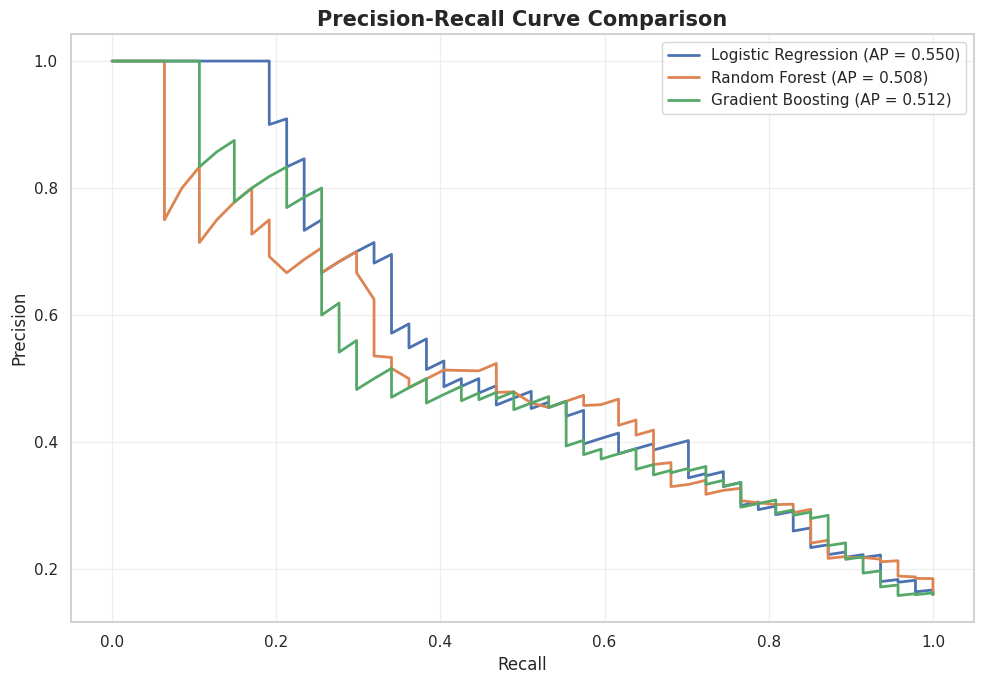

In [74]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Precision-Recall Curve Comparison

plt.figure(figsize=(10, 7))

for name, model in models.items():

    # Predict probabilities for employees who left (class 1)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Calculate Precision and Recall
    precision, recall, _ = precision_recall_curve(y_test, y_prob)

    # Calculate Average Precision
    ap_score = average_precision_score(y_test, y_prob)

    # Plot curve
    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f'{name} (AP = {ap_score:.3f})'
    )

plt.title('Precision-Recall Curve Comparison', fontsize=15, fontweight='bold')
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)

plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 11.6.1 Precision-Recall Findings and Model Selection - Key Findings

- Logistic Regression achieved the highest Average Precision (0.550) among the three final models evaluated at the default threshold.
- Random Forest achieved an Average Precision of 0.508.
- Gradient Boosting achieved an Average Precision of 0.512.
- Logistic Regression demonstrated comparatively better Precision-Recall performance.
- Model selection considers both predictive performance and the business objective of identifying employees at risk of attrition.
- The validation-tuned Logistic Regression threshold (0.764) achieved an F1 Score of 48.89% on the test set. This was lower than the full-training Logistic Regression model at threshold 0.50 (51.16%). Therefore, the full-training default-threshold model was retained as the final selected model.


## 11.7 Final Model Selection

The final model is selected by comparing the evaluated candidates using the F1 Score, while also considering recall and the project objective of identifying potential attrition cases.

In [75]:
# FINAL MODEL SELECTION

best_model_row = final_comparison.loc[
    final_comparison['F1 Score'].idxmax()
]

print("=" * 55)
print("FINAL SELECTED MODEL")
print("=" * 55)

print("Model:", best_model_row['Model'])
print("Accuracy:", best_model_row['Accuracy'], "%")
print("Precision:", best_model_row['Precision'], "%")
print("Recall:", best_model_row['Recall'], "%")
print("F1 Score:", best_model_row['F1 Score'], "%")
print("ROC-AUC:", best_model_row['ROC-AUC'])

print("\nReason for Selection:")
print("Highest F1 Score among the evaluated models.")

FINAL SELECTED MODEL
Model: Logistic Regression (0.50)
Accuracy: 78.57142857142857 %
Precision: 40.243902439024396 %
Recall: 70.2127659574468 %
F1 Score: 51.162790697674424 %
ROC-AUC: 0.797398570074942

Reason for Selection:
Highest F1 Score among the evaluated models.


## 11.8 Final Model Performance Audit


In [76]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

audit_results = []

# Audit the three final models at the default threshold (0.50)
for name, model in models.items():

    y_pred = model.predict(X_test_processed)

    class_1_index = list(model.classes_).index(1)
    y_prob = model.predict_proba(X_test_processed)[:, class_1_index]

    audit_results.append({
        'Model': f'{name} (0.50)',
        'Accuracy': accuracy_score(y_test, y_pred) * 100,
        'Precision': precision_score(y_test, y_pred, zero_division=0) * 100,
        'Recall': recall_score(y_test, y_pred, zero_division=0) * 100,
        'F1 Score': f1_score(y_test, y_pred, zero_division=0) * 100,
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'Average Precision': average_precision_score(y_test, y_prob)
    })

# Audit Logistic Regression at the optimized threshold
audit_results.append({
    'Model': f'Logistic Regression ({best_threshold:.3f})',
    'Accuracy': accuracy_score(y_test, y_test_optimized) * 100,
    'Precision': precision_score(y_test, y_test_optimized, zero_division=0) * 100,
    'Recall': recall_score(y_test, y_test_optimized, zero_division=0) * 100,
    'F1 Score': f1_score(y_test, y_test_optimized, zero_division=0) * 100,
    'ROC-AUC': roc_auc_score(y_test, y_test_prob),
    'Average Precision': average_precision_score(y_test, y_test_prob)
})

# Create the final audit table
audit_df = pd.DataFrame(audit_results)

audit_df = audit_df.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL PERFORMANCE AUDIT")
print("=" * 75)

display(audit_df.round(3))

FINAL MODEL PERFORMANCE AUDIT


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Logistic Regression (0.50),78.571,40.244,70.213,51.163,0.797,0.550
1,Logistic Regression (0.764),84.354,51.163,46.809,48.889,0.796,0.547
2,Random Forest (0.50),86.735,70.000,29.787,41.791,0.803,0.508
3,Gradient Boosting (0.50),84.014,50.000,29.787,37.333,0.787,0.512


# 12. Final Model Saving and Verification

The selected Logistic Regression model and its fitted preprocessing transformer are saved together as a reusable model bundle.

The saved bundle includes:

- Final trained Logistic Regression model
- Fitted preprocessing transformer
- Original input feature names
- Classification threshold (0.50)

This bundle can be reused for future employee attrition predictions without retraining the model or refitting the preprocessing transformer.

In [77]:
import joblib
import os

# Select the final Logistic Regression model
final_model = models['Logistic Regression']

# Create a reusable model bundle
model_bundle = {
    'model': final_model,
    'preprocessor': preprocessor,
    'feature_columns': X_train.columns.tolist(),
    'threshold': 0.50,
    'target_mapping': {
        0: 'Stayed',
        1: 'Left'
    }
}

# Save the complete bundle
model_path = '/content/employee_attrition_model_bundle.joblib'

joblib.dump(model_bundle, model_path)

# Verify the saved file
if os.path.exists(model_path):
    print("MODEL BUNDLE SAVED SUCCESSFULLY!")
    print("File Name:", os.path.basename(model_path))
    print("File Size:", round(os.path.getsize(model_path) / 1024, 2), "KB")
else:
    print("Model bundle could not be saved.")

MODEL BUNDLE SAVED SUCCESSFULLY!
File Name: employee_attrition_model_bundle.joblib
File Size: 7.54 KB


## 12.1 Verification of the Saved Model Bundle

The saved model bundle is reloaded to verify that the trained Logistic Regression model and fitted preprocessing transformer can be restored and used for employee attrition predictions.

In [78]:
# Reload the saved model bundle
loaded_bundle = joblib.load(model_path)

# Extract the saved components
loaded_model = loaded_bundle['model']
loaded_preprocessor = loaded_bundle['preprocessor']
loaded_features = loaded_bundle['feature_columns']
loaded_threshold = loaded_bundle['threshold']

# Prepare test data using the saved feature columns
X_test_saved = X_test[loaded_features]

# Apply the saved preprocessing transformer
X_test_saved_processed = loaded_preprocessor.transform(X_test_saved)

# Generate predictions using the loaded model
loaded_probabilities = loaded_model.predict_proba(
    X_test_saved_processed
)[:, list(loaded_model.classes_).index(1)]

loaded_predictions = (
    loaded_probabilities >= loaded_threshold
).astype(int)

# Display verification results
print("MODEL BUNDLE RELOADED SUCCESSFULLY!")
print("Model:", type(loaded_model).__name__)
print("Preprocessor:", type(loaded_preprocessor).__name__)
print("Classification Threshold:", loaded_threshold)
print("Test Records Processed:", len(loaded_predictions))
print("Predictions Generated:", len(loaded_predictions) == len(y_test))

MODEL BUNDLE RELOADED SUCCESSFULLY!
Model: LogisticRegression
Preprocessor: ColumnTransformer
Classification Threshold: 0.5
Test Records Processed: 294
Predictions Generated: True


# 13. Model Explainability - Logistic Regression

- Model Explainability helps us understand how different employee-related features influence the model's predictions.
- Logistic Regression uses coefficients to indicate the direction of association between each feature and the predicted attrition outcome.
- Positive coefficients indicate a higher predicted likelihood of employee attrition.
- Negative coefficients indicate a lower predicted likelihood of employee attrition.
- This analysis helps identify important factors associated with employee attrition and supports better business understanding.

Note: These coefficients represent model associations and do not establish cause-and-effect relationships.

TOP POSITIVE AND NEGATIVE COEFFICIENTS


,Feature,Coefficient
49,cat__JobRole_Sales Representative,1.5272
43,cat__JobRole_Laboratory Technician,1.3153
33,cat__EducationField_Human Resources,1.0123
28,cat__BusinessTravel_Travel_Frequently,0.9217
54,cat__OverTime_Yes,0.7845
11,num__NumCompaniesWorked,0.5493
52,cat__MaritalStatus_Single,0.4784
24,num__PromotionDelay,0.4447
19,num__YearsAtCompany,0.3998
42,cat__JobRole_Human Resources,0.3446


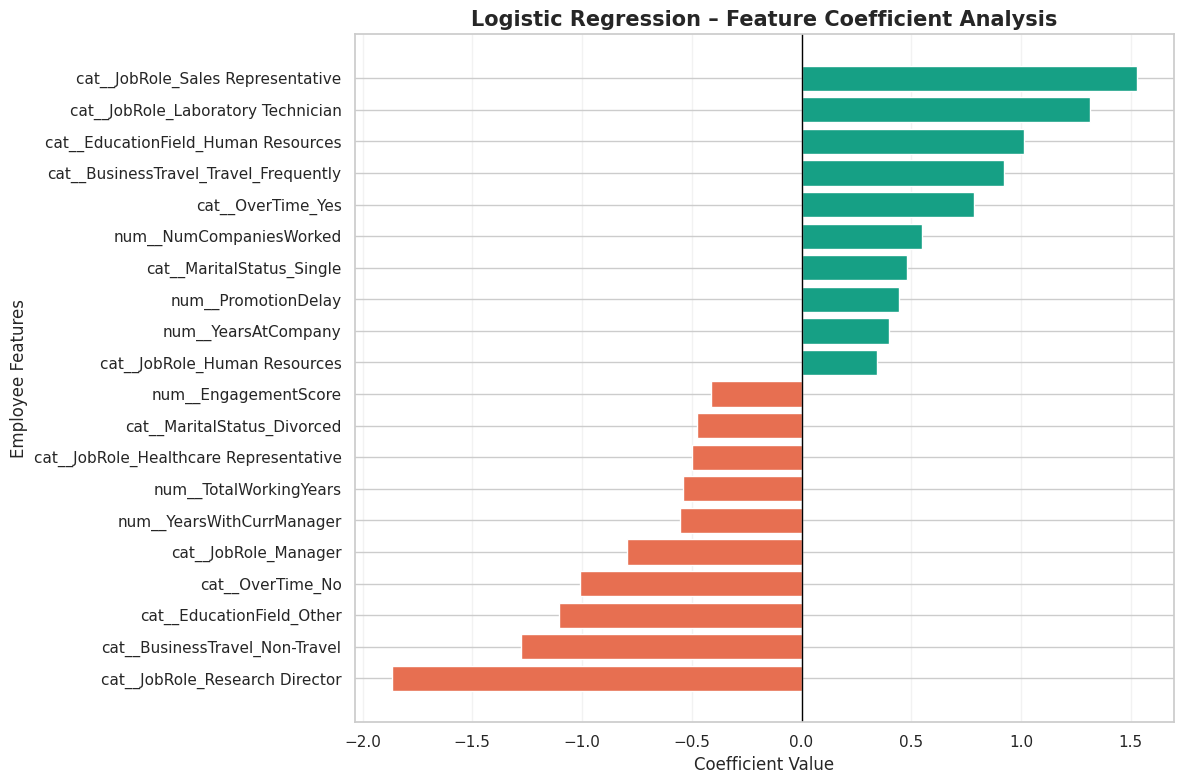

In [79]:
import pandas as pd
import matplotlib.pyplot as plt

# Get Logistic Regression model
lr_model = models['Logistic Regression']

# Extract model coefficients
coefficient_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lr_model.coef_[0]
})

# Sort coefficients
coefficient_df = coefficient_df.sort_values(
    by='Coefficient',
    ascending=False
)

# Select top 10 positive and negative features
top_positive = coefficient_df.head(10)
top_negative = coefficient_df.tail(10)

# Combine selected features
top_coefficients = pd.concat([
    top_positive,
    top_negative
])

# Display coefficient table
print("TOP POSITIVE AND NEGATIVE COEFFICIENTS")
display(top_coefficients.round(4))

# Visualize coefficients
plot_df = top_coefficients.sort_values(
    by='Coefficient',
    ascending=True
)

plt.figure(figsize=(12, 8))

colors = [
    '#16A085' if value > 0 else '#E76F51'
    for value in plot_df['Coefficient']
]

plt.barh(
    plot_df['Feature'],
    plot_df['Coefficient'],
    color=colors
)

plt.axvline(0, color='black', linewidth=1)

plt.title(
    'Logistic Regression – Feature Coefficient Analysis',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Coefficient Value', fontsize=12)
plt.ylabel('Employee Features', fontsize=12)

plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## 13.1 Logistic Regression Coefficient Analysis – Findings
The Logistic Regression coefficient analysis highlights several employee-related factors associated with attrition predictions.

**Key Findings:**

- Job roles such as Sales Representative and Laboratory Technician show positive coefficients, indicating a higher predicted likelihood of attrition compared with their respective reference categories.
- Frequent business travel and overtime are positively associated with attrition predictions.
- Employees with a higher number of previously worked companies also show a positive association with attrition.
- Features such as TotalWorkingYears, YearsWithCurrManager, and JobRole_Manager have negative coefficients, indicating a lower predicted likelihood of attrition.
- OverTime_No, BusinessTravel_Non-Travel, and JobRole_Research Director also show negative associations.


- HR teams can pay closer attention to employees in roles and work conditions associated with higher attrition predictions.
- Reviewing overtime practices and frequent travel requirements may help organizations identify potential employee concerns.
- Career development, manager-employee relationships, and employee engagement should be monitored as part of retention planning.
- Model predictions can support early identification of employees who may require additional attention.

### Conclusion

Logistic Regression provides an interpretable view of the relationship between employee characteristics and attrition predictions. These findings can help HR teams prioritize retention analysis and develop more informed employee engagement strategies.

**Note:** These results represent model-based associations, not proven causes of employee attrition.

## 13.2 SHAP-based Model Explainability

- SHAP is an explainability technique used to understand how individual features contribute to machine learning predictions.
- It helps identify which employee-related factors have a greater influence on the model's predictions.
- SHAP values indicate whether a feature pushes the prediction towards employee attrition or employee retention.
- SHAP provides both global feature importance and individual prediction explanations.

**Objective:** To understand the contribution of employee-related features in the Logistic Regression model's attrition predictions.

In [80]:
!pip -q install shap

In [81]:
import shap
import numpy as np
import matplotlib.pyplot as plt

# Select the final Logistic Regression model
final_model = models['Logistic Regression']

# Convert data into dense format if required
if hasattr(X_train_balanced, "toarray"):
    background_data = X_train_balanced.toarray()
else:
    background_data = np.asarray(X_train_balanced)

if hasattr(X_test_processed, "toarray"):
    test_data = X_test_processed.toarray()
else:
    test_data = np.asarray(X_test_processed)

# Select background and test samples
np.random.seed(42)

background_indices = np.random.choice(
    len(background_data),
    min(100, len(background_data)),
    replace=False
)

test_indices = np.random.choice(
    len(test_data),
    min(100, len(test_data)),
    replace=False
)

background_sample = background_data[background_indices]
X_explain = test_data[test_indices]

# Create SHAP Linear Explainer
explainer = shap.LinearExplainer(
    final_model,
    background_sample
)

# Calculate SHAP values
shap_values = explainer.shap_values(X_explain)

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_values = shap_values[1]

elif len(shap_values.shape) == 3:
    shap_values = shap_values[:, :, 1]

print("SHAP VALUES CALCULATED SUCCESSFULLY!")
print("Explained Samples:", len(X_explain))
print("Total Features:", len(feature_names))
print("SHAP Shape:", shap_values.shape)

SHAP VALUES CALCULATED SUCCESSFULLY!
Explained Samples: 100
Total Features: 55
SHAP Shape: (100, 55)


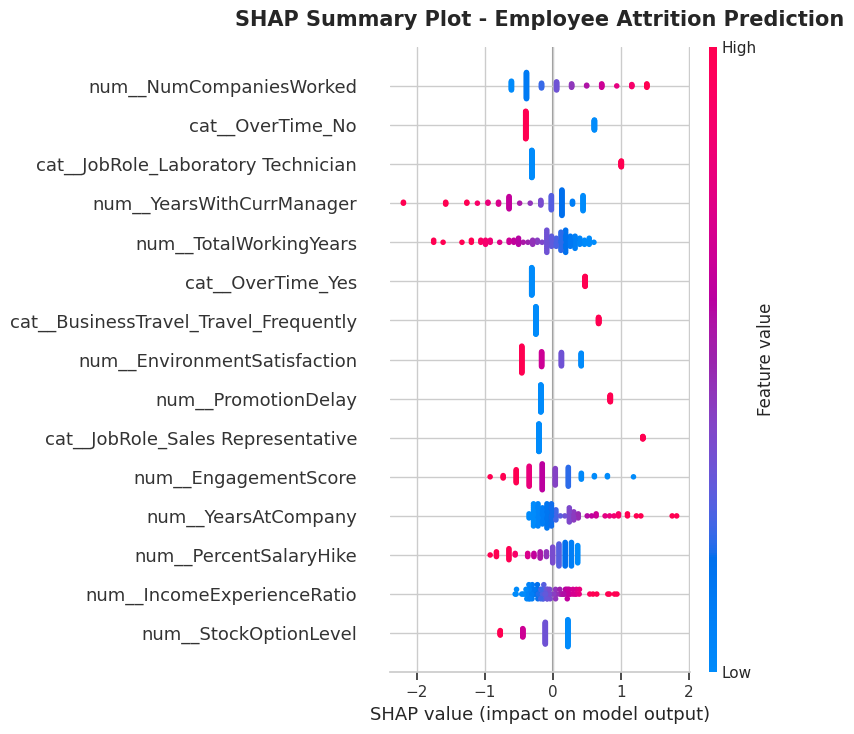

In [82]:
# SHAP Summary Plot

plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=feature_names,
    max_display=15,
    show=False
)

plt.title(
    'SHAP Summary Plot - Employee Attrition Prediction',
    fontsize=15,
    fontweight='bold',
    pad=15
)

plt.tight_layout()
plt.show()

TOP 15 FEATURES BASED ON SHAP IMPORTANCE


,Feature,Mean SHAP Value
11,num__NumCompaniesWorked,0.4681
53,cat__OverTime_No,0.4545
43,cat__JobRole_Laboratory Technician,0.4331
22,num__YearsWithCurrManager,0.4071
16,num__TotalWorkingYears,0.3774
54,cat__OverTime_Yes,0.3534
28,cat__BusinessTravel_Travel_Frequently,0.3281
4,num__EnvironmentSatisfaction,0.3181
24,num__PromotionDelay,0.3089
49,cat__JobRole_Sales Representative,0.3034


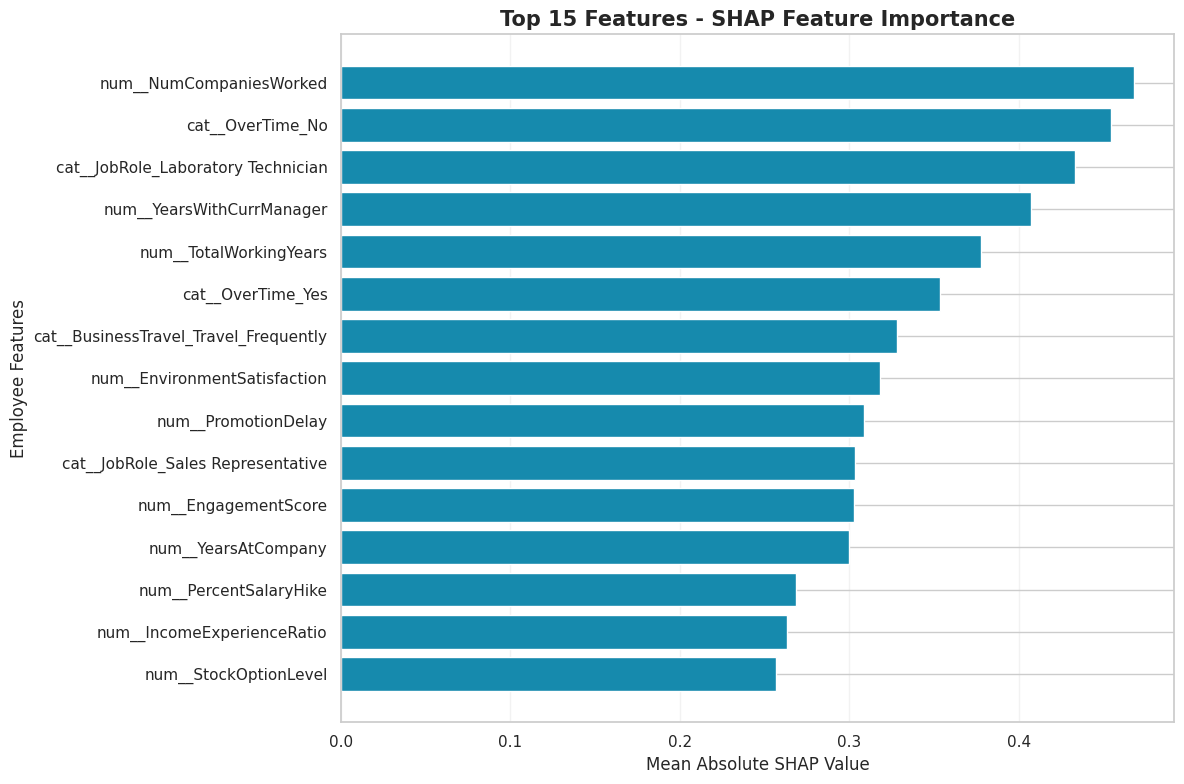

In [83]:
# Calculate Mean Absolute SHAP Values

mean_shap_values = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    'Feature': feature_names,
    'Mean SHAP Value': mean_shap_values
})

# Sort features by importance
shap_importance = shap_importance.sort_values(
    by='Mean SHAP Value',
    ascending=False
)

print("TOP 15 FEATURES BASED ON SHAP IMPORTANCE")
display(shap_importance.head(15).round(4))

# Plot Top 15 Features
top_shap = shap_importance.head(15).sort_values(
    by='Mean SHAP Value',
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_shap['Feature'],
    top_shap['Mean SHAP Value'],
    color='#168AAD'
)

plt.title(
    'Top 15 Features - SHAP Feature Importance',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Employee Features')

plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

### 13.2.1 SHAP Analysis – Key Findings

- NumCompaniesWorked emerged as the most influential feature, with a mean absolute SHAP value of 0.4681.
- OverTime_No (0.4545) and JobRole_Laboratory Technician (0.4331) were among the next most influential features.
- YearsWithCurrManager (0.4071) and TotalWorkingYears (0.3774) also showed considerable contributions to model predictions.
- BusinessTravel_Travel_Frequently, EnvironmentSatisfaction, and PromotionDelay were also identified as important features.
- EngagementScore and YearsAtCompany contributed to the model's predictions, highlighting the relevance of employee experience and workplace-related factors.

- HR teams can examine employees' previous job changes and career history to better understand employee retention patterns.
- Overtime and frequent business travel can be reviewed to identify potential workplace concerns.
- Employee satisfaction, engagement, and promotion opportunities should be monitored as part of retention planning.
- Employee-manager relationships and career development can be considered when designing employee retention initiatives.
- SHAP explanations can help HR teams understand which factors contribute most to individual employee predictions.

### Conclusion

SHAP analysis provides an additional layer of model explainability by identifying the employee-related features that contribute most to attrition predictions. It helps translate machine learning outputs into more understandable insights for HR decision-making.

**Note:** Mean absolute SHAP values represent the average magnitude of feature contributions, not their direction. These findings are based on 100 explained test samples and do not establish causal relationships.

## 13.3 Individual Employee Prediction Explanation

- This analysis explains how different employee features contribute to an individual employee's attrition prediction.

- Using SHAP Waterfall Plot, we can identify which features push the model's prediction towards Attrition or Retention.

- This provides a clearer understanding of individual model predictions and demonstrates the practical application of explainable AI in HR analytics.

INDIVIDUAL EMPLOYEE PREDICTION
--------------------------------
Predicted Attrition Probability: 28.9 %
Predicted Class: No Attrition


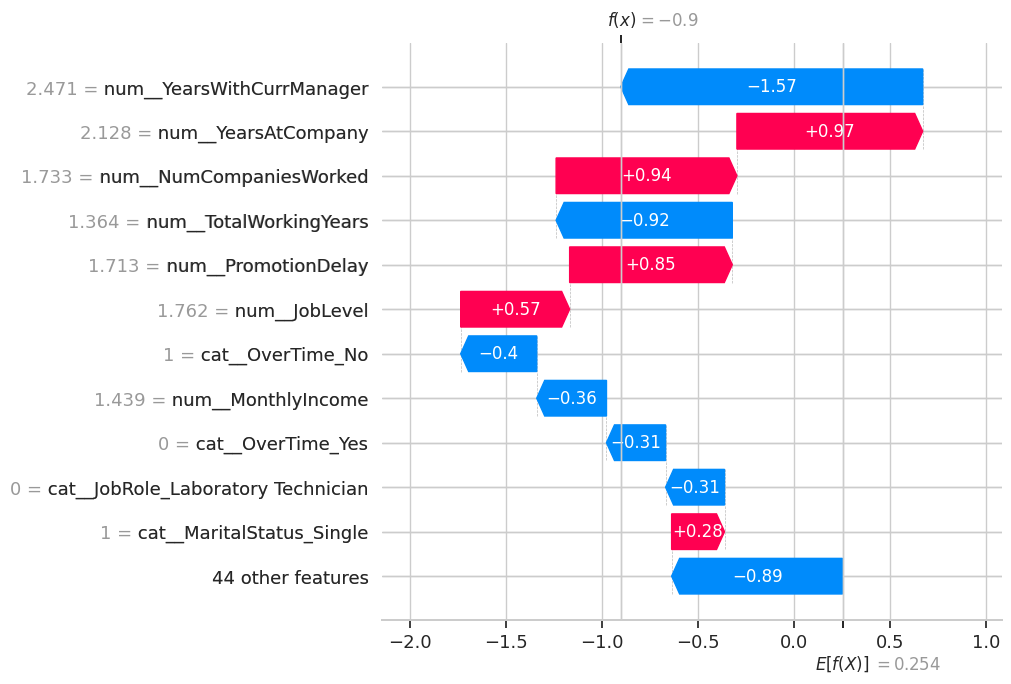

In [84]:
# Select one employee from the explained test samples
employee_data = X_explain[0:1]

# Predict attrition probability
attrition_probability = final_model.predict_proba(employee_data)[0][1]

# Display prediction
print("INDIVIDUAL EMPLOYEE PREDICTION")
print("--------------------------------")
print("Predicted Attrition Probability:",
      round(attrition_probability * 100, 2), "%")

if attrition_probability >= 0.50:
    print("Predicted Class: Attrition")
else:
    print("Predicted Class: No Attrition")

# Get SHAP base value
base_value = float(np.array(explainer.expected_value).reshape(-1)[0])

# Create SHAP explanation
individual_explanation = shap.Explanation(
    values=shap_values[0],
    base_values=base_value,
    data=employee_data[0],
    feature_names=feature_names
)

# Generate Waterfall Plot
shap.plots.waterfall(
    individual_explanation,
    max_display=12
)

### 13.3.1 Individual Prediction – Key Findings

- The selected employee received an attrition probability of 28.90%.
- Based on the 0.50 classification threshold, the model predicted No Attrition.

- YearsAtCompany, NumCompaniesWorked, and PromotionDelay contributed positively towards the attrition prediction.
- YearsWithCurrManager and TotalWorkingYears contributed negatively towards the attrition prediction.
- OverTime_No and MonthlyIncome also contributed towards a lower attrition prediction.
- The combined contributions of all features resulted in a predicted probability below the classification threshold.

- HR teams can use individual prediction explanations to understand the factors influencing model outputs.
- Employee career history, promotion patterns, and manager relationships can be considered during retention analysis.
- SHAP explanations can help make machine learning predictions more transparent and understandable.

### Conclusion

Individual SHAP analysis demonstrates how different employee features contribute to a specific attrition prediction. It provides a practical example of explainable AI in employee attrition analysis.

**Note:** This is a model prediction for one test sample and should not be treated as a definitive assessment of an actual employee.

# 14. Employee Attrition Risk Scoring

Risk scoring assigns an attrition probability to each employee using the selected Logistic Regression model.

Based on the predicted probability, employees are grouped into three illustrative risk categories:

- Low Risk: Below 30%
- Medium Risk: 30%–60% (inclusive)
- High Risk: Above 60%

This helps demonstrate how machine learning predictions can be organized into understandable risk groups for employee retention analysis.

Note: These categories are illustrative thresholds for this project and are not validated HR risk standards.

In [85]:
import numpy as np
import pandas as pd

# Select the final Logistic Regression model
final_model = models['Logistic Regression']

# Predict attrition probabilities for test employees
class_1_index = list(final_model.classes_).index(1)
attrition_probabilities = final_model.predict_proba(X_test_processed)[:, class_1_index]

# Create risk scoring dataframe
risk_df = X_test.copy()

# Store attrition probability in both formats
risk_df['Attrition_Probability'] = attrition_probabilities
risk_df['Attrition_Probability(%)'] = attrition_probabilities * 100

# Assign risk categories
conditions = [
    risk_df['Attrition_Probability(%)'] < 30,
    risk_df['Attrition_Probability(%)'].between(30, 60, inclusive='both'),
    risk_df['Attrition_Probability(%)'] > 60,
]
choices = ['Low Risk', 'Medium Risk', 'High Risk']

risk_df['Risk_Category'] = np.select(conditions, choices, default='Unclassified')

# Add actual attrition status for evaluation
risk_df['Actual_Attrition'] = y_test.values

# Display employee risk scores
print("EMPLOYEE ATTRITION RISK SCORING")
print("=" * 45)

cols_to_show = [
    'Attrition_Probability',
    'Attrition_Probability(%)',
    'Risk_Category',
    'Actual_Attrition',
]

# Ensure we are indexing columns properly
display(risk_df.loc[:, cols_to_show].head(15))

# Risk category distribution
print("\nRISK CATEGORY DISTRIBUTION")
risk_distribution = (
    risk_df['Risk_Category']
    .value_counts()
    .reindex(['Low Risk', 'Medium Risk', 'High Risk'], fill_value=0)
)
display(risk_distribution.to_frame(name='Employee Count'))

EMPLOYEE ATTRITION RISK SCORING


,Attrition_Probability,Attrition_Probability(%),Risk_Category,Actual_Attrition
1061,0.254817,25.481748,Low Risk,0
891,0.013046,1.304573,Low Risk,0
456,0.278012,27.801227,Low Risk,0
922,0.011185,1.118523,Low Risk,0
69,0.825868,82.586756,High Risk,1
1164,0.748322,74.832169,High Risk,0
406,0.059966,5.996589,Low Risk,0
1330,0.141932,14.193199,Low Risk,0
1232,0.012139,1.213887,Low Risk,0
1311,0.310938,31.093825,Medium Risk,0



RISK CATEGORY DISTRIBUTION


,Employee Count
Risk_Category,
Low Risk,168
Medium Risk,63
High Risk,63


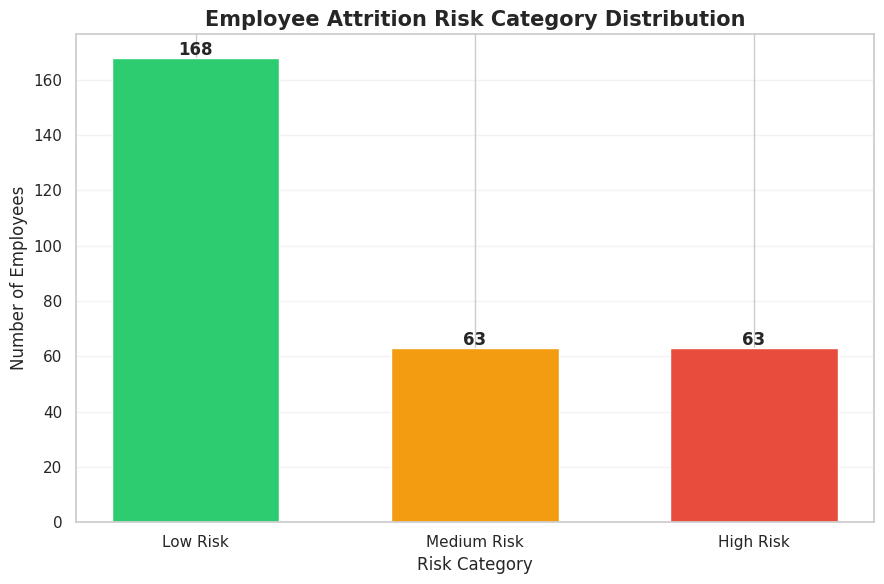

In [86]:
import matplotlib.pyplot as plt

risk_counts = risk_df['Risk_Category'].value_counts().reindex(
    ['Low Risk', 'Medium Risk', 'High Risk'],
    fill_value=0
)

colors = ['#2ECC71', '#F39C12', '#E74C3C']

plt.figure(figsize=(9, 6))

bars = plt.bar(
    risk_counts.index,
    risk_counts.values,
    color=colors,
    width=0.6
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        str(int(height)),
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

plt.title(
    'Employee Attrition Risk Category Distribution',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Risk Category')
plt.ylabel('Number of Employees')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## 14.1 Risk Category Analysis - Key Findings

The risk scoring analysis categorizes 294 test employees into three attrition risk groups based on their predicted attrition probabilities.

- Low Risk: 168 employees (57.14%) fall into this category.
- Medium Risk: 63 employees (21.43%) fall into this category.
- High Risk: 63 employees (21.43%) fall into this category.
- More than half of the evaluated employees fall under the Low Risk category.
- The Medium and High Risk categories each contain 63 employees, representing 42.86% of the test dataset combined.
- Actual attrition rates increase across the predicted risk categories: 5.95% for Low Risk, 15.87% for Medium Risk, and 42.86% for High Risk.
- HR teams can use risk categories to prioritize employees for further retention analysis.
- Employees in the High Risk category may be considered for closer review of workplace satisfaction, career development, and workload conditions.
- Medium Risk employees can be monitored through regular engagement and feedback activities.
- Risk scores should be used as decision-support information rather than as definitive judgments about individual employees.

### Conclusion

The Employee Attrition Risk Scoring system converts model-generated probabilities into three understandable risk categories. The increasing actual attrition rates across these categories indicate that the risk-scoring approach provides useful information for employee attrition monitoring and retention planning.

**Note:** These risk categories are based on illustrative probability thresholds and should not be treated as validated HR standards. The analysis covers the test dataset, not the entire workforce.

## 14.2 Risk Category vs Actual Attrition Analysis

- This analysis evaluates the relationship between predicted employee attrition risk categories and actual attrition outcomes in the test dataset.

- The employees are grouped into Low Risk, Medium Risk, and High Risk categories based on their predicted attrition probabilities.

- By comparing the actual attrition rate across these categories, we can assess whether employees assigned higher risk scores also show higher observed attrition rates.

**Objective:** To evaluate the usefulness of the risk categorization by comparing predicted risk levels with actual employee attrition outcomes.

In [87]:
# Calculate actual attrition count by risk category

risk_comparison = pd.crosstab(
    risk_df['Risk_Category'],
    risk_df['Actual_Attrition']
)

# Ensure all risk categories and both attrition classes are present
risk_comparison = risk_comparison.reindex(
    index=['Low Risk', 'Medium Risk', 'High Risk'],
    columns=[0, 1],
    fill_value=0
)

# Rename columns
risk_comparison.columns = [
    'No Attrition',
    'Attrition'
]

print("RISK CATEGORY VS ACTUAL ATTRITION")
display(risk_comparison)

# Calculate actual attrition percentage
risk_comparison['Actual Attrition Rate (%)'] = (
    risk_comparison['Attrition'] /
    (risk_comparison['Attrition'] + risk_comparison['No Attrition'])
) * 100

print("\nACTUAL ATTRITION RATE BY RISK CATEGORY")
display(
    risk_comparison[
        ['Actual Attrition Rate (%)']
    ].round(2)
)

RISK CATEGORY VS ACTUAL ATTRITION


,No Attrition,Attrition
Risk_Category,,
Low Risk,158,10
Medium Risk,53,10
High Risk,36,27



ACTUAL ATTRITION RATE BY RISK CATEGORY


,Actual Attrition Rate (%)
Risk_Category,
Low Risk,5.95
Medium Risk,15.87
High Risk,42.86


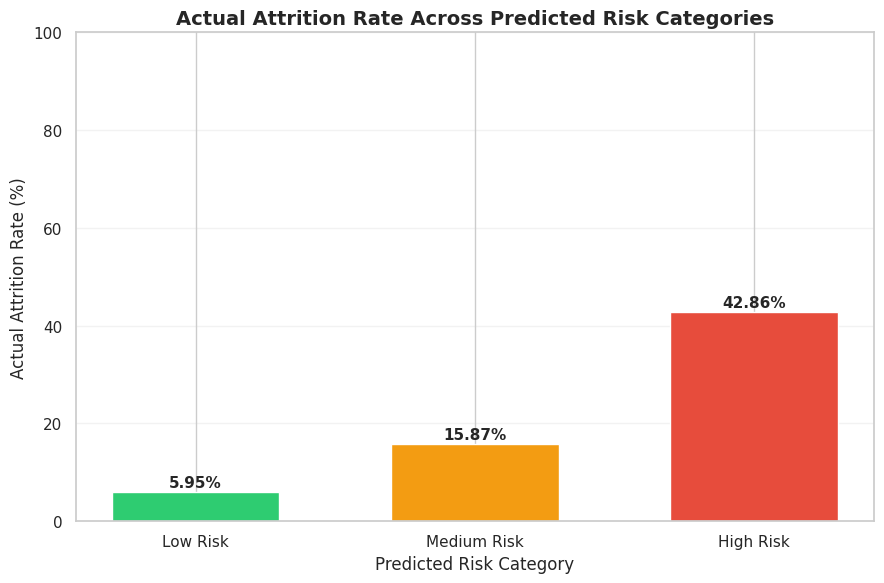

In [88]:
# Extract actual attrition rates
attrition_rates = risk_comparison[
    'Actual Attrition Rate (%)'
]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    attrition_rates.index,
    attrition_rates.values,
    color=['#2ECC71', '#F39C12', '#E74C3C'],
    width=0.6
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f'{height:.2f}%',
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

plt.title(
    'Actual Attrition Rate Across Predicted Risk Categories',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Predicted Risk Category')
plt.ylabel('Actual Attrition Rate (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

### 14.2.1 Risk Category Analysis – Key Findings

The analysis shows an increasing pattern in actual employee attrition rates across the predicted risk categories.

- Low Risk: This category recorded an actual attrition rate of 5.95% (10 out of 168 employees), indicating a relatively low level of attrition in this group.
- Medium Risk: This category recorded an actual attrition rate of 15.87% (10 out of 63 employees), indicating a higher attrition rate than the Low Risk group.
- High Risk: This category recorded the highest actual attrition rate of 42.86% (27 out of 63 employees), showing that attrition cases were more concentrated in this group.
- HR teams can use these risk categories to identify employee groups that may require additional attention.
- High-risk employees may be prioritized for supportive engagement discussions, feedback collection, and retention initiatives.
- Medium-risk employees can be monitored through regular feedback and workplace satisfaction assessments.
- Low-risk employees can continue to be supported through existing employee engagement practices.

### Conclusion
The actual attrition rate increases progressively from the Low Risk category to the High Risk category. This indicates that the model's risk-scoring approach provides useful insights for employee attrition monitoring and can support data-informed HR planning.

**Note:** These findings are based on the test dataset of 294 employees. Risk categories are predictive indicators and should support—not replace—individual assessment and fair HR decision-making.

# 15. Business Interpretation and Key Findings

The Employee Attrition Prediction project provides insights into factors associated with employee turnover.

Key Findings

1. Logistic Regression (Default Threshold 0.50) achieved the highest F1 Score of 51.16% among the evaluated models.
2. Random Forest achieved the highest Accuracy of 86.73%, but its Recall was comparatively low at 29.79%.
3. Logistic Regression achieved an Average Precision (AP) of 0.550, outperforming Random Forest and Gradient Boosting.
4. Feature importance analysis highlighted factors such as Stock Option Level, Job Level, Overtime, Engagement Score, and Years With Current Manager.

## 15.1 Business Recommendations

- Monitor employees with comparatively low engagement scores.
- Review overtime patterns and workload distribution.
- Evaluate career growth and promotion opportunities.
- Examine employee satisfaction and workplace conditions.
- Use predictive insights to support employee retention strategies.

## 15.2 Business Interpretation – Conclusion

The project demonstrates how machine learning can support employee attrition analysis and help organizations identify employees who may be at risk of leaving.

Logistic Regression with the default classification threshold was selected based on its comparatively higher F1 Score and Recall among the evaluated models.

# 16. Final Project Conclusion

The Employee Attrition Prediction and Risk Scoring project demonstrates how machine learning can be used to analyze employee attrition patterns, estimate attrition probabilities, and categorize employees into different risk levels.

## 16.1 Key Project Outcomes

- Exploratory Data Analysis identified several employee-related factors associated with attrition, including overtime, job role, work experience, and job satisfaction.
- Feature engineering introduced four additional features: Income-to-Experience Ratio, Promotion Delay, Engagement Score, and Workload Stress.
- Logistic Regression, Random Forest, and Gradient Boosting models were trained and evaluated using a stratified train-test split and SMOTE applied to the training data.
- Logistic Regression trained on the full balanced training data with the default classification threshold of 0.50 was selected as the final model, achieving an F1 Score of 51.16%, Recall of 70.21%, and ROC-AUC of 0.797.
- The validation-tuned Logistic Regression model using threshold 0.764 achieved an F1 Score of 48.89%, Recall of 46.81%, and ROC-AUC of 0.796 on the test set. Its F1 Score was lower than the selected model, so it was retained as a comparison only.
- The risk scoring analysis categorized 294 test employees into Low, Medium, and High Risk groups. Their observed actual attrition rates were 5.95%, 15.87%, and 42.86%, respectively.
- Model explainability techniques, including Logistic Regression coefficients and SHAP analysis, were used to understand the factors influencing predictions.
- The final model and preprocessing pipeline were saved together and successfully reloaded and verified.

## 16.2 Limitations and Responsible Use

- The model's predictions are estimates and should not be treated as certain outcomes.
- Risk thresholds are illustrative and may require adjustment based on organizational requirements.
- Feature relationships indicate associations, not necessarily cause-and-effect relationships.
- The model should support human-led HR analysis rather than replace individual assessment or employment decisions.
- Further validation on new and larger datasets is recommended before real-world deployment.

## 16.3 Overall Conclusion

The project demonstrates an end-to-end machine learning workflow for employee attrition analysis, prediction, risk scoring, and explainability. It provides a foundation for developing an interactive HR analytics solution that can help organizations understand potential attrition risks and explore data-informed employee retention strategies.
